# Bitcoin Transaction Data Exploration



In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
DATA_DIR = Path.cwd()
if not (DATA_DIR / 'train.csv').exists():
    DATA_DIR = Path('/Users/yichuan/Desktop/Bitcoin')
TRAIN_PATH, TEST_PATH, EDGE_PATH = [DATA_DIR / name for name in ['train.csv', 'test.csv', 'txs_edgelist.csv']]
CHUNK_SIZE = 25_000
PLOT_SAMPLE_SIZE = 30_000
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    sns.set_theme(style='whitegrid')
    PLOTTING_AVAILABLE = True
except ImportError as error:
    PLOTTING_AVAILABLE = False
    print(f'Optional plotting packages unavailable: {error}')

for path in [TRAIN_PATH, TEST_PATH, EDGE_PATH]:
    print(path.name, f'{path.stat().st_size / 1024**2:.1f} MB' if path.exists() else 'missing')

train.csv missing
test.csv missing
txs_edgelist.csv missing


In [3]:

from google.colab import drive
import os
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Set and verify the dataset directory path
DATA_DIR = Path('/content/drive/My Drive/BT4012 Bitcoin')
TRAIN_PATH, TEST_PATH, EDGE_PATH = [DATA_DIR / name for name in ['train.csv', 'test.csv', 'txs_edgelist.csv']]

for path in [TRAIN_PATH, TEST_PATH, EDGE_PATH]:
    print(path.name, f'{path.stat().st_size / 1024**2:.1f} MB' if path.exists() else 'missing')


Mounted at /content/drive
train.csv 439.6 MB
test.csv 47.3 MB
txs_edgelist.csv 4.3 MB


# 1 Schema and dataset sizes

In [ ]:
def preview(path, nrows=5):
    if not path.exists():
        print(f'File not found: {path}')
        return None
    frame = pd.read_csv(path, nrows=nrows)
    print(f'{path.name}: preview shape={frame.shape}')
    display(frame.head())
    display(frame.dtypes.to_frame('dtype').T)
    return frame

def count_rows(path):
    if not path.exists():
        return np.nan
    return sum(len(chunk) for chunk in pd.read_csv(path, usecols=[0], chunksize=CHUNK_SIZE))

train_preview = preview(TRAIN_PATH)
test_preview = preview(TEST_PATH)
edge_preview = preview(EDGE_PATH)
train_rows, test_rows, edge_rows = [count_rows(path) for path in [TRAIN_PATH, TEST_PATH, EDGE_PATH]]
print(f'rows: train={train_rows:,}, test={test_rows:,}, edges={edge_rows:,}')
feature_cols = [column for column in train_preview.columns if column.startswith('feat_')] if train_preview is not None else []
print(f'feature columns: {len(feature_cols)}')

train.csv: preview shape=(5, 168)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
dtype,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


test.csv: preview shape=(5, 168)


,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,2.262621,1.947206,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,...,-0.524789,-0.531617,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,2,198827545,36,-0.172282,0.837998,1.018602,0.553368,-0.043875,0.641758,-0.061584,...,1.149152,1.070472,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
3,3,200997190,36,-0.172926,0.156148,1.573595,-0.046932,-0.043875,-0.029140,-0.061584,...,0.125358,0.080204,1.461330,1.461369,0.018279,-0.049041,-0.038193,-0.011377,-1.760926,-1.760984
4,4,200996856,36,-0.171396,1.311640,1.573595,0.478330,-0.004174,0.474034,-0.061584,...,-0.106650,-0.137402,0.258822,0.729391,0.018279,0.393121,0.680158,0.462432,0.359796,1.091185


,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
dtype,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


txs_edgelist.csv: preview shape=(5, 2)


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


,txId1,txId2
dtype,int64,int64


rows: train=141,772, test=15,329, edges=234,355
feature columns: 165


# 2 Full training-data quality checks


In [ ]:
def collect_quality(path):
    total = 0
    duplicates = 0
    ids = set()
    missing = None
    time_counts = {}
    label_counts = {}
    time_min, time_max = np.inf, -np.inf
    for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE):
        total += len(chunk)
        duplicates += int(chunk.duplicated().sum())
        ids.update(chunk['txId'].dropna().astype(str))
        missing = chunk.isna().sum() if missing is None else missing.add(chunk.isna().sum(), fill_value=0)
        for key, value in chunk['time_step'].value_counts().items():
            time_counts[key] = time_counts.get(key, 0) + int(value)
        for key, value in chunk['label'].astype('string').fillna('<NA>').value_counts().items():
            label_counts[str(key)] = label_counts.get(str(key), 0) + int(value)
        time_min = min(time_min, chunk['time_step'].min())
        time_max = max(time_max, chunk['time_step'].max())
    return {'rows': total, 'unique_txId': len(ids), 'duplicates': duplicates,
            'missing': missing.sort_values(ascending=False),
            'time_counts': pd.Series(time_counts).sort_index(),
            'label_counts': pd.Series(label_counts).sort_index(),
            'time_min': time_min, 'time_max': time_max}

quality = collect_quality(TRAIN_PATH)
print(f"rows={quality['rows']:,}; unique txId={quality['unique_txId']:,}; duplicate rows within chunks={quality['duplicates']:,}")
print(f"time range={quality['time_min']} to {quality['time_max']}")
display(quality['label_counts'].rename('count').to_frame())
display(quality['missing'][quality['missing'] > 0].rename('missing_count').to_frame().head(20))

rows=141,772; unique txId=141,772; duplicate rows within chunks=0
time range=1 to 35


,count
0.0,27591
1.0,3644
<NA>,110537


,missing_count
label,110537


# 3 Labels, imbalance, time coverage, and feature distributions

,count,share
0.0,27591,0.194615
1.0,3644,0.025703
<NA>,110537,0.779681


Observed labels: ['0.0', '1.0', '<NA>']
Feature summary:


,count,mean,std,min,25%,50%,75%,max
feat_1,30000.0,0.011704,0.717920,-0.172983,-0.171934,-0.167938,-0.141382,17.557653
feat_2,30000.0,-0.161804,0.129942,-0.210553,-0.184668,-0.184668,-0.158783,11.620132
feat_3,30000.0,-0.868003,0.729104,-1.756361,-1.201369,-1.201369,-1.201369,2.128587
feat_4,30000.0,0.015409,1.023153,-0.121970,-0.121970,-0.121970,-0.046932,47.526848
feat_5,30000.0,-0.004886,1.534493,-0.063725,-0.043875,-0.043875,-0.043875,260.090707
feat_6,30000.0,0.005160,0.969985,-0.113002,-0.113002,-0.113002,-0.029140,48.023923
feat_7,30000.0,0.032647,0.772620,-0.061584,-0.061584,-0.061584,-0.061584,43.452763
feat_8,30000.0,0.012119,0.719785,-0.163646,-0.163568,-0.161999,-0.146763,17.977420
feat_9,30000.0,0.011619,0.715864,-0.169460,-0.168554,-0.165117,-0.141826,17.717359
feat_10,30000.0,0.002865,0.639643,-0.049707,-0.049707,-0.049707,-0.044544,58.073150


,missing_rate
feat_1,0.0
feat_2,0.0
feat_3,0.0
feat_4,0.0
feat_5,0.0
feat_6,0.0
feat_7,0.0
feat_8,0.0
feat_9,0.0
feat_10,0.0


,dataset,min_time_step,max_time_step,unique_time_steps
0,train,1,35,35
1,test,36,49,14


Test starts after train: True


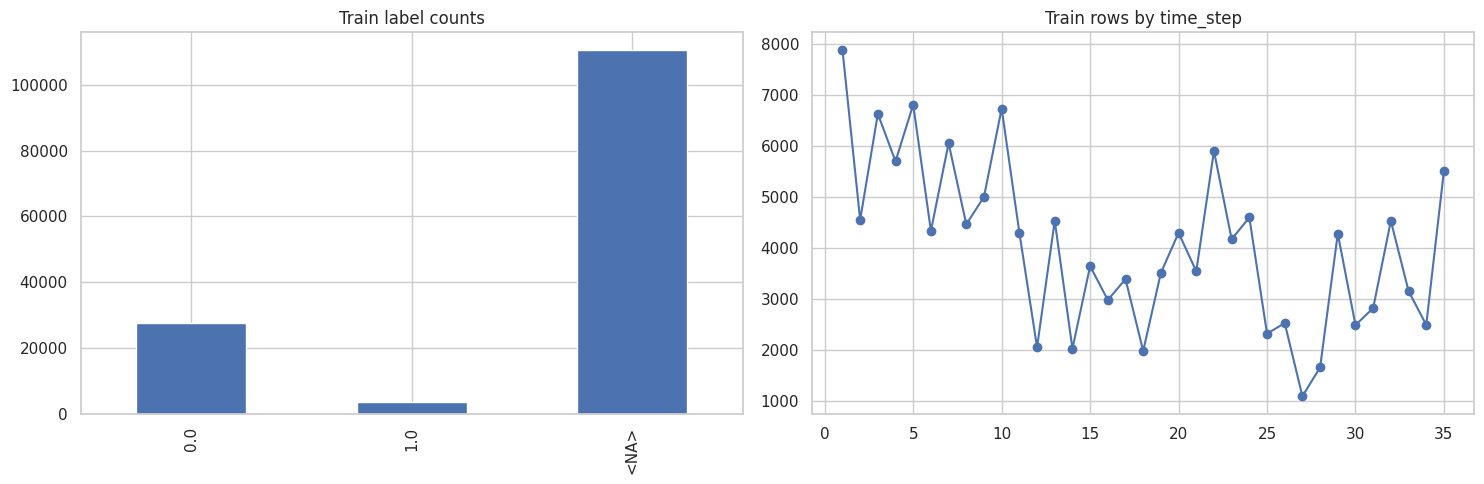

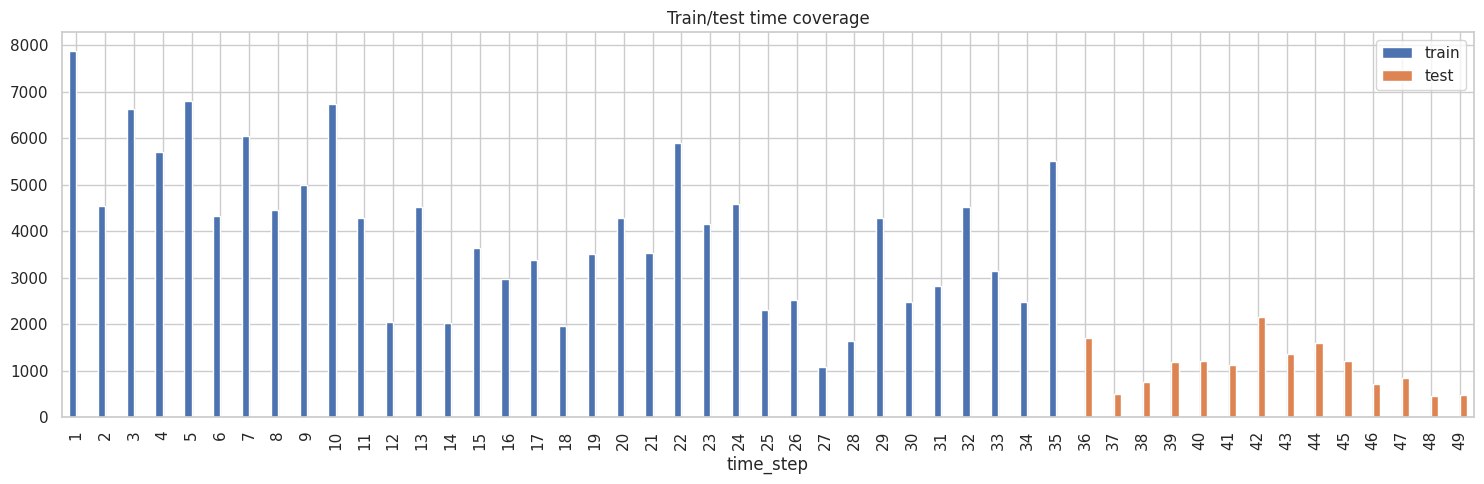

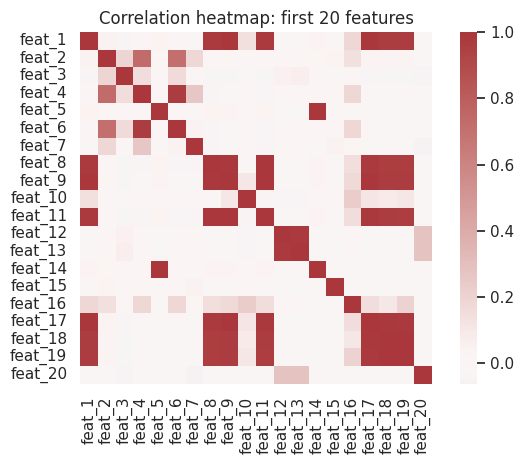

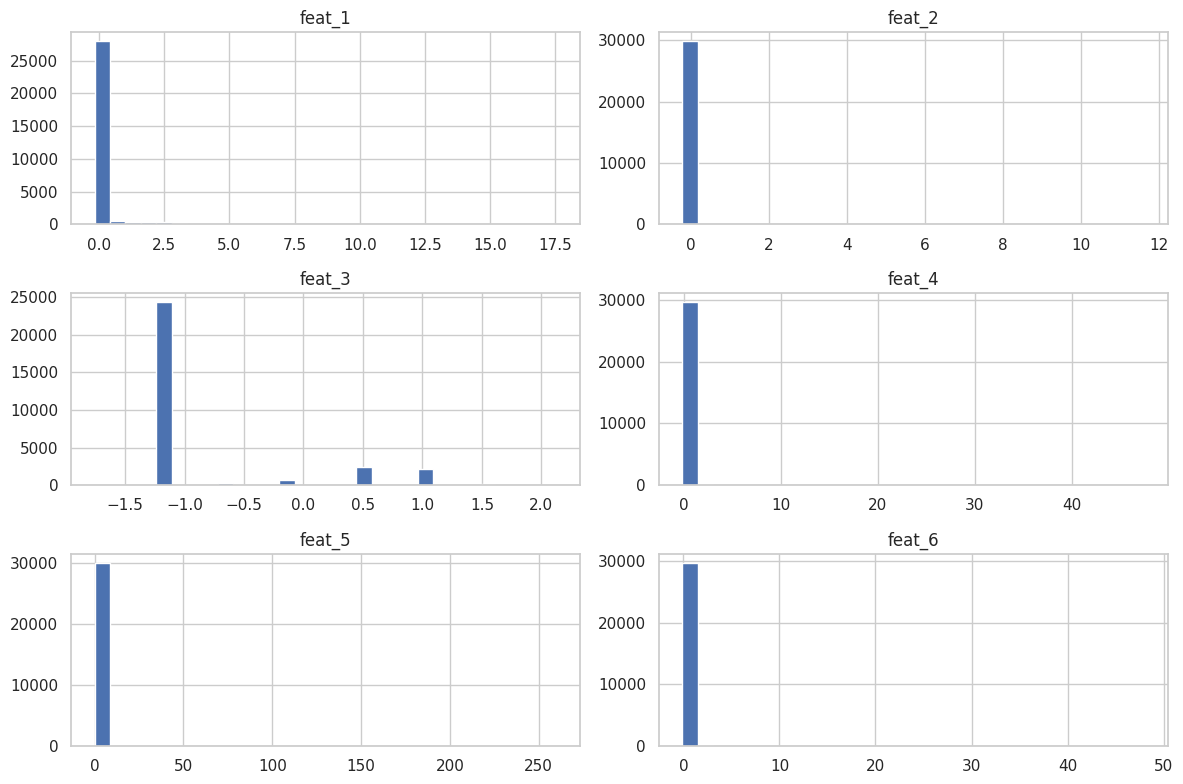

In [ ]:
label_table = quality['label_counts'].rename('count').to_frame()
label_table['share'] = label_table['count'] / label_table['count'].sum()
display(label_table)
print('Observed labels:', sorted(label_table.index.astype(str)))
train_sample = pd.read_csv(TRAIN_PATH, nrows=PLOT_SAMPLE_SIZE)
test_sample = pd.read_csv(TEST_PATH, nrows=min(PLOT_SAMPLE_SIZE, int(test_rows)))
print('Feature summary:')
display(train_sample[feature_cols].describe().T.head(20))
display(train_sample[feature_cols].isna().mean().sort_values(ascending=False).head(20).rename('missing_rate').to_frame())

def all_times(path):
    return pd.concat((chunk['time_step'] for chunk in pd.read_csv(path, usecols=['time_step'], chunksize=CHUNK_SIZE)), ignore_index=True)

train_times, test_times = all_times(TRAIN_PATH), all_times(TEST_PATH)
coverage = pd.DataFrame({'dataset': ['train', 'test'], 'min_time_step': [train_times.min(), test_times.min()], 'max_time_step': [train_times.max(), test_times.max()], 'unique_time_steps': [train_times.nunique(), test_times.nunique()]})
display(coverage)
print('Test starts after train:', bool(test_times.min() > train_times.max()))
if PLOTTING_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    label_table['count'].plot.bar(ax=axes[0], title='Train label counts')
    quality['time_counts'].plot(ax=axes[1], marker='o', title='Train rows by time_step')
    plt.tight_layout(); plt.show()
    pd.DataFrame({'train': train_times.value_counts().sort_index(), 'test': test_times.value_counts().sort_index()}).fillna(0).plot.bar(figsize=(15, 5), title='Train/test time coverage')
    plt.tight_layout(); plt.show()
    train_sample[feature_cols[:20]].corr().pipe(sns.heatmap, cmap='vlag', center=0, square=True)
    plt.title('Correlation heatmap: first 20 features'); plt.tight_layout(); plt.show()
    train_sample[feature_cols[:6]].hist(figsize=(12, 8), bins=30); plt.tight_layout(); plt.show()
else:
    print('Plotting skipped because matplotlib/seaborn is unavailable.')

# 4 Basic graph exploration


edge rows=234,355; graph nodes=203,769; matched train sample=30,000/30,000 (100.00%)


,count,mean,std,min,50%,90%,99%,max
in_degree,203769.0,1.150101,3.911132,0.0,1.0,1.0,9.0,284.0
out_degree,203769.0,1.150101,1.894740,0.0,1.0,2.0,5.0,472.0
total_degree,203769.0,2.300203,4.328377,1.0,2.0,3.0,13.0,473.0


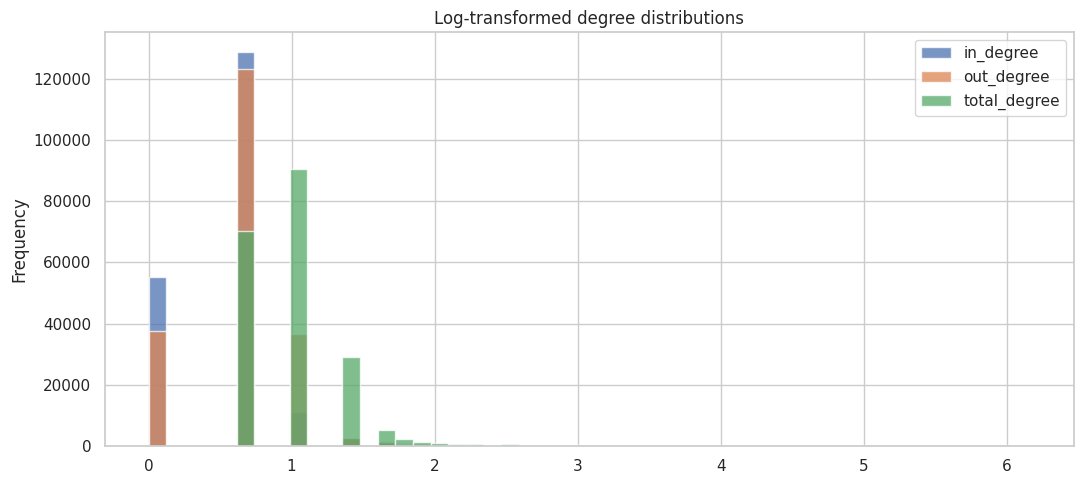

In [ ]:
edges = pd.read_csv(EDGE_PATH, usecols=['txId1', 'txId2'])
in_degree = edges['txId2'].value_counts().rename('in_degree')
out_degree = edges['txId1'].value_counts().rename('out_degree')
graph_features = pd.concat([in_degree, out_degree], axis=1).fillna(0)
graph_features['total_degree'] = graph_features['in_degree'] + graph_features['out_degree']
graph_features.index = graph_features.index.astype(str)
sample_ids = set(train_sample['txId'].astype(str))
matched = graph_features.loc[graph_features.index.intersection(sample_ids)]
print(f'edge rows={len(edges):,}; graph nodes={len(graph_features):,}; matched train sample={len(matched):,}/{len(sample_ids):,} ({len(matched) / len(sample_ids):.2%})')
display(graph_features.describe(percentiles=[.5, .9, .99]).T)
if PLOTTING_AVAILABLE:
    np.log1p(graph_features).plot.hist(bins=50, alpha=.75, figsize=(11, 5), title='Log-transformed degree distributions')
    plt.tight_layout(); plt.show()

# 5 Time-based validation and next steps

Use time_step to separate train and validiate sets, which ensures no leakage for training.

In [ ]:
available_times = np.sort(train_sample['time_step'].dropna().unique())
if len(available_times) >= 3:
    cutoff = available_times[int(len(available_times) * 0.8)]
    past = train_sample[train_sample.time_step < cutoff]
    future = train_sample[train_sample.time_step >= cutoff]
    print(f'cutoff={cutoff}; past rows={len(past):,}; future validation rows={len(future):,}')
    print(f'past range={past.time_step.min()}..{past.time_step.max()}; future range={future.time_step.min()}..{future.time_step.max()}')

print('Recommendations:')
print('- Exclude unknown/none/NA labels from supervised targets.')
print('- Evaluate PR-AUC, recall, precision, and calibrated probabilities for class imbalance.')
print('- Add graph degree features and inspect time distribution shift before modeling.')
print('- Use time-based validation and check for feature leakage before test predictions.')

cutoff=5; past rows=24,738; future validation rows=5,262
past range=1..4; future range=5..5
Recommendations:
- Exclude unknown/none/NA labels from supervised targets.
- Evaluate PR-AUC, recall, precision, and calibrated probabilities for class imbalance.
- Add graph degree features and inspect time distribution shift before modeling.
- Use time-based validation and check for feature leakage before test predictions.


# 6 Supervised Experiments with basic graph features

This section builds a reproducible supervised-learning pipeline. Only transactions with non-missing `label` values from `train.csv` are used as labeled examples; unlabeled transactions are excluded from target training rather than treated as negative cases. All transactions may still contribute to graph-derived features.

Two feature configurations are compared:

- **Model A — Baseline:** anonymous `feat_*` features;
- **Model B — Graph-enhanced:** `feat_*` features plus transaction-level `in_degree`, `out_degree`, and `total_degree`.

Both configurations use `HistGradientBoostingClassifier` with class-balanced sample weights to account for label imbalance. Validation follows a temporal split: transactions with `time_step ≤ 28` are used for training, while transactions with `time_step ≥ 29` form the validation set.

After evaluation, each model is refitted using all labeled training transactions and used to generate test probabilities. Submissions are saved using the exact `index,target` structure and row ordering from `sample_submission.csv`.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score

# Load the complete tables. The edge-derived features use the observed full graph.
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
edges = pd.read_csv(EDGE_PATH, usecols=['txId1', 'txId2'])

feature_cols = [column for column in train.columns if column.startswith('feat_')]
base_cols = feature_cols

graph_features = pd.concat([
    edges['txId2'].value_counts().rename('in_degree'),
    edges['txId1'].value_counts().rename('out_degree'),
], axis=1).fillna(0)
graph_features.index = graph_features.index.astype(str)
graph_features['total_degree'] = graph_features['in_degree'] + graph_features['out_degree']

def add_graph_features(frame):
    result = frame.copy()
    graph_part = graph_features.reindex(result['txId'].astype(str)).fillna(0)
    for column in graph_features.columns:
        result[column] = graph_part[column].to_numpy()
    return result

train_model = add_graph_features(train)
test_model = add_graph_features(test)
labelled = train_model[train_model['label'].notna()].copy()
labelled['label'] = labelled['label'].astype(int)

train_part = labelled[labelled['time_step'] <= 28]
valid_part = labelled[labelled['time_step'] >= 29]
print(f'labelled={len(labelled):,}; train={len(train_part):,}; validation={len(valid_part):,}')
print(f'train positives={train_part.label.mean():.3f}; validation positives={valid_part.label.mean():.3f}')
print(f'graph nodes={len(graph_features):,}; edges={len(edges):,}')

labelled=31,235; train=25,207; validation=6,028
train positives=0.101; validation positives=0.183
graph nodes=203,769; edges=234,355


In [ ]:
def class_weights(labels):
    counts = labels.value_counts()
    total = len(labels)
    return labels.map({int(cls): total / (2 * count) for cls, count in counts.items()}).to_numpy()

model_specs = {
    'baseline': feature_cols,
    'graph_degree': feature_cols + ['in_degree', 'out_degree', 'total_degree'],
}
validation_results = []
trained_models = {}

for model_name, columns in model_specs.items():
    model = HistGradientBoostingClassifier(
        max_iter=180,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42,
    )
    model.fit(
        train_part[columns],
        train_part['label'],
        sample_weight=class_weights(train_part['label']),
    )
    valid_probability = model.predict_proba(valid_part[columns])[:, 1]
    valid_prediction = (valid_probability >= 0.5).astype(int)
    validation_results.append({
        'model': model_name,
        'pr_auc': average_precision_score(valid_part['label'], valid_probability),
        'roc_auc': roc_auc_score(valid_part['label'], valid_probability),
        'precision_at_0.5': precision_score(valid_part['label'], valid_prediction, zero_division=0),
        'recall_at_0.5': recall_score(valid_part['label'], valid_prediction, zero_division=0),
    })
    trained_models[model_name] = model

validation_results = pd.DataFrame(validation_results).sort_values('pr_auc', ascending=False)
display(validation_results)

# Refit each experiment on every labelled training transaction before predicting test.
for model_name, columns in model_specs.items():
    final_model = HistGradientBoostingClassifier(
        max_iter=180,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42,
    )
    final_model.fit(
        labelled[columns],
        labelled['label'],
        sample_weight=class_weights(labelled['label']),
    )
    test_probability = final_model.predict_proba(test_model[columns])[:, 1]
    submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
    submission['target'] = test_probability
    assert submission['index'].equals(test['index'])
    assert submission['target'].between(0, 1).all()
    output_path = DATA_DIR / f'submission_{model_name}.csv'
    submission.to_csv(output_path, index=False)
    print(f'{output_path.name}: rows={len(submission):,}; target_mean={test_probability.mean():.4f}')

,model,pr_auc,roc_auc,precision_at_0.5,recall_at_0.5
0,baseline,0.983225,0.995455,0.938462,0.941016
1,graph_degree,0.983139,0.995438,0.946642,0.933757


submission_baseline.csv: rows=15,329; target_mean=0.0589
submission_graph_degree.csv: rows=15,329; target_mean=0.0627


# 7 Degree-feature ablation

Abalation tests for 3 sets of graph features`in_degree`，`out_degree` , and both，and testing `log1p` transversion

In [ ]:
ablation_train = train_model.copy()
ablation_test = test_model.copy()
for column in ['in_degree', 'out_degree', 'total_degree']:
    ablation_train[f'log_{column}'] = np.log1p(ablation_train[column])
    ablation_test[f'log_{column}'] = np.log1p(ablation_test[column])

def make_classifier():
    return HistGradientBoostingClassifier(
        max_iter=180,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42,
    )

def make_sample_weights(labels):
    counts = labels.value_counts()
    total = len(labels)
    weights = {int(cls): total / (2 * count) for cls, count in counts.items()}
    return labels.map(weights).to_numpy()

ablation_specs = {
    'in_degree_only': feature_cols + ['in_degree'],
    'out_degree_only': feature_cols + ['out_degree'],
    'log_degree_only': feature_cols + ['log_total_degree'],
    'log_in_out': feature_cols + ['log_in_degree', 'log_out_degree'],
}
ablation_results = []
for model_name, columns in ablation_specs.items():
    model = make_classifier()
    model.fit(
        ablation_train.loc[train_part.index, columns],
        train_part['label'],
        sample_weight=make_sample_weights(train_part['label']),
    )
    probability = model.predict_proba(ablation_train.loc[valid_part.index, columns])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    ablation_results.append({
        'model': model_name,
        'pr_auc': average_precision_score(valid_part['label'], probability),
        'roc_auc': roc_auc_score(valid_part['label'], probability),
        'precision_at_0.5': precision_score(valid_part['label'], prediction, zero_division=0),
        'recall_at_0.5': recall_score(valid_part['label'], prediction, zero_division=0),
    })

ablation_results = pd.DataFrame(ablation_results).sort_values('pr_auc', ascending=False)
display(ablation_results)

for model_name, columns in ablation_specs.items():
    final_model = make_classifier()
    final_model.fit(
        ablation_train.loc[labelled.index, columns],
        labelled['label'],
        sample_weight=make_sample_weights(labelled['label']),
    )
    probability = final_model.predict_proba(ablation_test[columns])[:, 1]
    submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
    submission['target'] = probability
    assert submission['index'].equals(test['index'])
    assert submission['target'].between(0, 1).all()
    output_path = DATA_DIR / f'submission_{model_name}.csv'
    submission.to_csv(output_path, index=False)
    print(f'{output_path.name}: target_mean={probability.mean():.4f}')

,model,pr_auc,roc_auc,precision_at_0.5,recall_at_0.5
0,in_degree_only,0.983990,0.996082,0.941441,0.948276
3,log_in_out,0.983871,0.996037,0.942986,0.945554
1,out_degree_only,0.983339,0.995440,0.943327,0.936479
2,log_degree_only,0.981537,0.994694,0.942096,0.930127


submission_in_degree_only.csv: target_mean=0.0602
submission_out_degree_only.csv: target_mean=0.0583
submission_log_degree_only.csv: target_mean=0.0634
submission_log_in_out.csv: target_mean=0.0602


# 8 Neighbor feature aggregation

Generate neighbour features based on neighbour means of 12 features.

In [ ]:
from sklearn.feature_selection import f_classif

selection_X = train_part[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
selection_scores, _ = f_classif(selection_X, train_part['label'])
selected_neighbor_features = [
    feature_cols[index]
    for index in np.argsort(np.nan_to_num(selection_scores, nan=-np.inf))[-12:]
]
print('selected neighbor features:', selected_neighbor_features)

node_lookup = pd.concat([
    train_model[['txId'] + selected_neighbor_features],
    test_model[['txId'] + selected_neighbor_features],
], ignore_index=True)
node_lookup['txId'] = node_lookup['txId'].astype(str)
node_lookup = node_lookup.drop_duplicates('txId').set_index('txId')

edge_source_values = edges.copy()
edge_source_values['txId1'] = edge_source_values['txId1'].astype(str)
edge_source_values['txId2'] = edge_source_values['txId2'].astype(str)
source_values = edge_source_values[['txId1', 'txId2']].join(node_lookup, on='txId1')
pred_aggregates = source_values.groupby('txId2')[selected_neighbor_features].mean()
pred_aggregates.columns = [f'pred_mean_{column}' for column in selected_neighbor_features]

target_values = edge_source_values[['txId1', 'txId2']].join(node_lookup, on='txId2')
succ_aggregates = target_values.groupby('txId1')[selected_neighbor_features].mean()
succ_aggregates.columns = [f'succ_mean_{column}' for column in selected_neighbor_features]
neighbor_features = pred_aggregates.join(succ_aggregates, how='outer').fillna(0)

def add_neighbor_features(frame):
    result = frame.copy()
    mapped = neighbor_features.reindex(result['txId'].astype(str)).fillna(0)
    mapped.index = result.index
    return result.join(mapped)

neighbor_train = add_neighbor_features(train_model)
neighbor_test = add_neighbor_features(test_model)
neighbor_columns = list(neighbor_features.columns)
neighbor_specs = {
    'neighbor_means': feature_cols + neighbor_columns,
}
neighbor_results = []
for model_name, columns in neighbor_specs.items():
    model = make_classifier()
    model.fit(
        neighbor_train.loc[train_part.index, columns],
        train_part['label'],
        sample_weight=make_sample_weights(train_part['label']),
    )
    probability = model.predict_proba(neighbor_train.loc[valid_part.index, columns])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    neighbor_results.append({
        'model': model_name,
        'pr_auc': average_precision_score(valid_part['label'], probability),
        'roc_auc': roc_auc_score(valid_part['label'], probability),
        'precision_at_0.5': precision_score(valid_part['label'], prediction, zero_division=0),
        'recall_at_0.5': recall_score(valid_part['label'], prediction, zero_division=0),
    })
display(pd.DataFrame(neighbor_results))

for model_name, columns in neighbor_specs.items():
    final_model = make_classifier()
    final_model.fit(
        neighbor_train.loc[labelled.index, columns],
        labelled['label'],
        sample_weight=make_sample_weights(labelled['label']),
    )
    probability = final_model.predict_proba(neighbor_test[columns])[:, 1]
    submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
    submission['target'] = probability
    assert submission['index'].equals(test['index'])
    output_path = DATA_DIR / f'submission_{model_name}.csv'
    submission.to_csv(output_path, index=False)
    print(f'{output_path.name}: target_mean={probability.mean():.4f}')

selected neighbor features: ['feat_103', 'feat_54', 'feat_112', 'feat_142', 'feat_150', 'feat_52', 'feat_148', 'feat_91', 'feat_90', 'feat_55', 'feat_89', 'feat_53']


,model,pr_auc,roc_auc,precision_at_0.5,recall_at_0.5
0,neighbor_means,0.982578,0.995388,0.931655,0.940109


submission_neighbor_means.csv: target_mean=0.0587


# 9 Combined features: degree + neighbor aggregates

Previous experiments tested degree features and neighbor aggregates separately. Here we combine them and also enrich neighbor aggregates with **std, min, max** (not just mean), and use the top 30 features instead of 12.

In [ ]:
# --- Richer neighbor aggregation: top-30 features × {mean, std, min, max} ---

top_k = 30
selection_X = train_part[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
selection_scores, _ = f_classif(selection_X, train_part['label'])
top_k_features = [
    feature_cols[i]
    for i in np.argsort(np.nan_to_num(selection_scores, nan=-np.inf))[-top_k:]
]
print(f'Top-{top_k} features for neighbor aggregation: {top_k_features}')

# Build node lookup with top-k features (all train + test nodes)
node_lookup_k = pd.concat([
    train_model[['txId'] + top_k_features],
    test_model[['txId'] + top_k_features],
], ignore_index=True)
node_lookup_k['txId'] = node_lookup_k['txId'].astype(str)
node_lookup_k = node_lookup_k.drop_duplicates('txId').set_index('txId')

edges_str = edges.copy()
edges_str['txId1'] = edges_str['txId1'].astype(str)
edges_str['txId2'] = edges_str['txId2'].astype(str)

# Predecessor aggregation (edges point txId1 -> txId2, predecessors of v are txId1 where txId2==v)
source_vals = edges_str[['txId1', 'txId2']].join(node_lookup_k, on='txId1')
pred_agg = source_vals.groupby('txId2')[top_k_features].agg(['mean', 'std', 'min', 'max'])
pred_agg.columns = [f'pred_{stat}_{feat}' for feat, stat in pred_agg.columns]
pred_agg = pred_agg.fillna(0)

# Successor aggregation (successors of v are txId2 where txId1==v)
target_vals = edges_str[['txId1', 'txId2']].join(node_lookup_k, on='txId2')
succ_agg = target_vals.groupby('txId1')[top_k_features].agg(['mean', 'std', 'min', 'max'])
succ_agg.columns = [f'succ_{stat}_{feat}' for feat, stat in succ_agg.columns]
succ_agg = succ_agg.fillna(0)

rich_neighbor_features = pred_agg.join(succ_agg, how='outer').fillna(0)
rich_neighbor_cols = list(rich_neighbor_features.columns)
print(f'Rich neighbor feature columns: {len(rich_neighbor_cols)}')

def add_rich_neighbor(frame):
    result = frame.copy()
    mapped = rich_neighbor_features.reindex(result['txId'].astype(str)).fillna(0)
    mapped.index = result.index
    return result.join(mapped)

combined_train = add_rich_neighbor(ablation_train)
combined_test = add_rich_neighbor(ablation_test)

# Feature groups for combined experiments
degree_cols = ['in_degree', 'out_degree', 'total_degree',
               'log_in_degree', 'log_out_degree', 'log_total_degree']

combined_specs = {
    'feat_only':           feature_cols,
    'feat+degree':         feature_cols + degree_cols,
    'feat+rich_neighbor':  feature_cols + rich_neighbor_cols,
    'feat+degree+rich_neighbor': feature_cols + degree_cols + rich_neighbor_cols,
}

combined_results = []
for name, cols in combined_specs.items():
    model = make_classifier()
    model.fit(
        combined_train.loc[train_part.index, cols],
        train_part['label'],
        sample_weight=make_sample_weights(train_part['label']),
    )
    prob = model.predict_proba(combined_train.loc[valid_part.index, cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    combined_results.append({
        'model': name,
        'pr_auc': average_precision_score(valid_part['label'], prob),
        'roc_auc': roc_auc_score(valid_part['label'], prob),
        'precision': precision_score(valid_part['label'], pred, zero_division=0),
        'recall': recall_score(valid_part['label'], pred, zero_division=0),
    })

combined_results_df = pd.DataFrame(combined_results).sort_values('pr_auc', ascending=False)
display(combined_results_df)

# Generate submission for best combined model
best_combined_name = combined_results_df.iloc[0]['model']
best_combined_cols = combined_specs[best_combined_name]
final_model = make_classifier()
final_model.fit(
    combined_train.loc[labelled.index, best_combined_cols],
    labelled['label'],
    sample_weight=make_sample_weights(labelled['label']),
)
prob = final_model.predict_proba(combined_test[best_combined_cols])[:, 1]
submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
submission['target'] = prob
output_path = DATA_DIR / f'submission_combined_best.csv'
submission.to_csv(output_path, index=False)
print(f'\nBest combined model: {best_combined_name}')
print(f'{output_path.name}: target_mean={prob.mean():.4f}')

Top-30 features for neighbor aggregation: ['feat_86', 'feat_93', 'feat_77', 'feat_79', 'feat_156', 'feat_67', 'feat_61', 'feat_65', 'feat_59', 'feat_84', 'feat_83', 'feat_85', 'feat_81', 'feat_80', 'feat_114', 'feat_136', 'feat_100', 'feat_101', 'feat_103', 'feat_54', 'feat_112', 'feat_142', 'feat_150', 'feat_52', 'feat_148', 'feat_91', 'feat_90', 'feat_55', 'feat_89', 'feat_53']
Rich neighbor feature columns: 240


,model,pr_auc,roc_auc,precision,recall
2,feat+rich_neighbor,0.986632,0.996467,0.944646,0.944646
3,feat+degree+rich_neighbor,0.983454,0.996022,0.941871,0.941016
0,feat_only,0.983225,0.995455,0.938462,0.941016
1,feat+degree,0.983139,0.995438,0.946642,0.933757



Best combined model: feat+rich_neighbor
submission_combined_best.csv: target_mean=0.0559


# 10 Rolling time-based validation

Replace the single train/valid split with 3-fold expanding-window validation. This better estimates generalization to future time steps and detects temporal overfitting.

In [ ]:
# --- Rolling time-based cross-validation ---

time_folds = [
    {'train': (1, 20), 'valid': (21, 25)},
    {'train': (1, 25), 'valid': (26, 30)},
    {'train': (1, 30), 'valid': (31, 35)},
]

# Use the best combined feature set from Section 9
best_cols = combined_specs[best_combined_name]

fold_results = []
for i, fold in enumerate(time_folds):
    t_lo, t_hi = fold['train']
    v_lo, v_hi = fold['valid']
    fold_train = combined_train[
        (combined_train['time_step'] >= t_lo) &
        (combined_train['time_step'] <= t_hi) &
        (combined_train['label'].notna())
    ].copy()
    fold_valid = combined_train[
        (combined_train['time_step'] >= v_lo) &
        (combined_train['time_step'] <= v_hi) &
        (combined_train['label'].notna())
    ].copy()
    if len(fold_valid) == 0:
        print(f'Fold {i}: no validation data in time_step {v_lo}-{v_hi}, skipping')
        continue
    fold_train['label'] = fold_train['label'].astype(int)
    fold_valid['label'] = fold_valid['label'].astype(int)

    model = make_classifier()
    model.fit(
        fold_train[best_cols],
        fold_train['label'],
        sample_weight=make_sample_weights(fold_train['label']),
    )
    prob = model.predict_proba(fold_valid[best_cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    fold_results.append({
        'fold': i,
        'train_time': f'{t_lo}-{t_hi}',
        'valid_time': f'{v_lo}-{v_hi}',
        'train_size': len(fold_train),
        'valid_size': len(fold_valid),
        'pos_rate_train': fold_train['label'].mean(),
        'pos_rate_valid': fold_valid['label'].mean(),
        'pr_auc': average_precision_score(fold_valid['label'], prob),
        'roc_auc': roc_auc_score(fold_valid['label'], prob),
        'precision': precision_score(fold_valid['label'], pred, zero_division=0),
        'recall': recall_score(fold_valid['label'], pred, zero_division=0),
    })

fold_df = pd.DataFrame(fold_results)
display(fold_df)
print(f'\nMean PR-AUC across folds: {fold_df["pr_auc"].mean():.4f} ± {fold_df["pr_auc"].std():.4f}')
print(f'Mean ROC-AUC across folds: {fold_df["roc_auc"].mean():.4f} ± {fold_df["roc_auc"].std():.4f}')

,fold,train_time,valid_time,train_size,valid_size,pos_rate_train,pos_rate_valid,pr_auc,roc_auc,precision,recall
0,0,1-20,21-25,18889,5311,0.093758,0.106571,0.851847,0.931667,0.861004,0.787986
1,1,1-25,26-30,24200,2705,0.096570,0.228096,0.983413,0.994345,0.938111,0.933549
2,2,1-30,31-35,26905,4330,0.109794,0.159353,0.992955,0.998336,0.871928,0.976812



Mean PR-AUC across folds: 0.9427 ± 0.0789
Mean ROC-AUC across folds: 0.9748 ± 0.0374


# 11 Multi-model comparison: Logistic Regression, XGBoost, LightGBM

Compare multiple classifiers on the same feature set to find the best learner. Uses the single time split (train ≤ 28, valid ≥ 29) for fast iteration.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import xgboost as xgb
import lightgbm as lgb

best_cols = combined_specs[best_combined_name]
pos_count = int(train_part['label'].sum())
neg_count = len(train_part) - pos_count
scale_pos = neg_count / max(pos_count, 1)

classifiers = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(
            class_weight='balanced', max_iter=1000, C=0.1, random_state=42
        )),
    ]),
    'HistGBT': make_classifier(),
    'XGBoost': xgb.XGBClassifier(
        n_estimators=200,
        learning_rate=0.08,
        max_depth=6,
        scale_pos_weight=scale_pos,
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        verbosity=0,
    ),
    'LightGBM': lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        scale_pos_weight=scale_pos,
        random_state=42,
        verbose=-1,
    ),
}

multi_model_results = []
trained_multi = {}

for name, clf in classifiers.items():
    use_weight = name == 'HistGBT'
    fit_kwargs = {}
    if use_weight:
        fit_kwargs['sample_weight'] = make_sample_weights(train_part['label'])

    clf.fit(combined_train.loc[train_part.index, best_cols], train_part['label'], **fit_kwargs)
    prob = clf.predict_proba(combined_train.loc[valid_part.index, best_cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    multi_model_results.append({
        'model': name,
        'pr_auc': average_precision_score(valid_part['label'], prob),
        'roc_auc': roc_auc_score(valid_part['label'], prob),
        'precision': precision_score(valid_part['label'], pred, zero_division=0),
        'recall': recall_score(valid_part['label'], pred, zero_division=0),
    })
    trained_multi[name] = clf

multi_model_df = pd.DataFrame(multi_model_results).sort_values('pr_auc', ascending=False)
display(multi_model_df)

,model,pr_auc,roc_auc,precision,recall
1,HistGBT,0.986632,0.996467,0.944646,0.944646
3,LightGBM,0.985537,0.996703,0.980880,0.931034
2,XGBoost,0.982708,0.995956,0.962721,0.937387
0,LogisticRegression,0.588118,0.899688,0.369060,0.965517


# 12 Ensemble: blending top models

Average predicted probabilities from the top tree-based models. Blending diverse learners typically improves calibration and reduces variance.

In [ ]:
# --- Ensemble: average of HistGBT, XGBoost, LightGBM ---

ensemble_models = ['HistGBT', 'XGBoost', 'LightGBM']
valid_probs = {}
for name in ensemble_models:
    valid_probs[name] = trained_multi[name].predict_proba(
        combined_train.loc[valid_part.index, best_cols]
    )[:, 1]

# Simple average ensemble
ensemble_prob = np.mean([valid_probs[n] for n in ensemble_models], axis=0)
ensemble_pred = (ensemble_prob >= 0.5).astype(int)

ensemble_result = {
    'model': 'Ensemble (avg)',
    'pr_auc': average_precision_score(valid_part['label'], ensemble_prob),
    'roc_auc': roc_auc_score(valid_part['label'], ensemble_prob),
    'precision': precision_score(valid_part['label'], ensemble_pred, zero_division=0),
    'recall': recall_score(valid_part['label'], ensemble_pred, zero_division=0),
}

# Combine with individual results
all_results = pd.concat([multi_model_df, pd.DataFrame([ensemble_result])], ignore_index=True)
all_results = all_results.sort_values('pr_auc', ascending=False)
display(all_results)

# --- Generate ensemble submission ---
# Refit all 3 models on full labelled data, then average test predictions
ensemble_test_probs = []
for name, clf_template in classifiers.items():
    if name not in ensemble_models:
        continue
    import copy
    clf = copy.deepcopy(clf_template) if not isinstance(clf_template, Pipeline) else clf_template
    use_weight = name == 'HistGBT'
    fit_kwargs = {}
    if use_weight:
        fit_kwargs['sample_weight'] = make_sample_weights(labelled['label'])
    clf.fit(combined_train.loc[labelled.index, best_cols], labelled['label'], **fit_kwargs)
    ensemble_test_probs.append(
        clf.predict_proba(combined_test[best_cols])[:, 1]
    )

ensemble_test_prob = np.mean(ensemble_test_probs, axis=0)
submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
submission['target'] = ensemble_test_prob
output_path = DATA_DIR / 'submission_ensemble.csv'
submission.to_csv(output_path, index=False)
print(f'{output_path.name}: target_mean={ensemble_test_prob.mean():.4f}')

,model,pr_auc,roc_auc,precision,recall
0,HistGBT,0.986632,0.996467,0.944646,0.944646
4,Ensemble (avg),0.986238,0.996717,0.969101,0.939201
1,LightGBM,0.985537,0.996703,0.980880,0.931034
2,XGBoost,0.982708,0.995956,0.962721,0.937387
3,LogisticRegression,0.588118,0.899688,0.369060,0.965517


submission_ensemble.csv: target_mean=0.0523


# 13 Higher-order graph features: 2-hop aggregates, PageRank, clustering coefficient, component size

Degree and 1-hop neighbor means only capture immediate connectivity. This section adds:
- **2-hop neighbor aggregates** — statistics of neighbors-of-neighbors
- **PageRank** — global importance / flow centrality
- **Local clustering coefficient** — how tightly connected a node's neighborhood is (fraud rings form clusters)
- **Connected component size** — isolates vs. large components

In [ ]:
import networkx as nx
from collections import defaultdict
import lightgbm as lgb

# Build directed graph (reuse edges already loaded)
G = nx.from_pandas_edgelist(edges, source='txId1', target='txId2', create_using=nx.DiGraph())
G_undirected = G.to_undirected()
print(f'Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')

# --- PageRank ---
pagerank = nx.pagerank(G, alpha=0.85, max_iter=100)
print(f'PageRank computed for {len(pagerank)} nodes')

# --- HITS ---
hubs, authorities = nx.hits(G, max_iter=100, normalized=True)

# --- Local clustering coefficient (undirected) ---
clustering = nx.clustering(G_undirected)

# --- Connected component size (undirected) ---
component_size = {}
for comp in nx.connected_components(G_undirected):
    sz = len(comp)
    for node in comp:
        component_size[node] = sz

# --- 2-hop neighbor aggregate (mean of 1-hop neighbors' degree) ---
# For each node, collect the set of 2-hop neighbors via undirected graph
two_hop_in_degree = {}
two_hop_out_degree = {}
two_hop_count = {}
for node in G.nodes():
    neighbors_1 = set(G_undirected.neighbors(node))
    neighbors_2 = set()
    for n1 in neighbors_1:
        neighbors_2.update(G_undirected.neighbors(n1))
    neighbors_2.discard(node)
    neighbors_2 -= neighbors_1
    two_hop_count[node] = len(neighbors_2)
    if neighbors_2:
        two_hop_in_degree[node] = np.mean([G.in_degree(n) for n in neighbors_2])
        two_hop_out_degree[node] = np.mean([G.out_degree(n) for n in neighbors_2])
    else:
        two_hop_in_degree[node] = 0.0
        two_hop_out_degree[node] = 0.0

# Assemble into DataFrame
graph_advanced = pd.DataFrame({
    'pagerank': pagerank,
    'hub_score': hubs,
    'authority_score': authorities,
    'clustering_coeff': clustering,
    'component_size': component_size,
    'two_hop_count': two_hop_count,
    'two_hop_mean_in_deg': two_hop_in_degree,
    'two_hop_mean_out_deg': two_hop_out_degree,
})
graph_advanced.index = graph_advanced.index.astype(str)
graph_advanced['log_pagerank'] = np.log1p(graph_advanced['pagerank'])
graph_advanced['log_component_size'] = np.log1p(graph_advanced['component_size'])
advanced_graph_cols = list(graph_advanced.columns)
print(f'Advanced graph features: {advanced_graph_cols}')

def add_advanced_graph(frame):
    result = frame.copy()
    mapped = graph_advanced.reindex(result['txId'].astype(str)).fillna(0)
    mapped.index = result.index
    for col in advanced_graph_cols:
        result[col] = mapped[col].values
    return result

combined_train = add_advanced_graph(combined_train)
combined_test = add_advanced_graph(combined_test)

# Evaluate
graph_adv_specs = {
    'best_cols (baseline)': best_cols,
    'best+advanced_graph': best_cols + advanced_graph_cols,
}
graph_adv_results = []
for name, cols in graph_adv_specs.items():
    clf = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.08, num_leaves=31,
        scale_pos_weight=scale_pos, random_state=42, verbose=-1,
    )
    clf.fit(combined_train.loc[train_part.index, cols], train_part['label'])
    prob = clf.predict_proba(combined_train.loc[valid_part.index, cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    graph_adv_results.append({
        'model': name,
        'pr_auc': average_precision_score(valid_part['label'], prob),
        'roc_auc': roc_auc_score(valid_part['label'], prob),
        'precision': precision_score(valid_part['label'], pred, zero_division=0),
        'recall': recall_score(valid_part['label'], pred, zero_division=0),
    })

graph_adv_df = pd.DataFrame(graph_adv_results).sort_values('pr_auc', ascending=False)
display(graph_adv_df)

Graph: 203769 nodes, 234355 edges
PageRank computed for 203769 nodes
Advanced graph features: ['pagerank', 'hub_score', 'authority_score', 'clustering_coeff', 'component_size', 'two_hop_count', 'two_hop_mean_in_deg', 'two_hop_mean_out_deg', 'log_pagerank', 'log_component_size']


,model,pr_auc,roc_auc,precision,recall
1,best+advanced_graph,0.986730,0.997089,0.980132,0.940109
0,best_cols (baseline),0.985537,0.996703,0.980880,0.931034


# 14 Personalized PageRank (PPR) for Fraud Detection

Standard PageRank acts as a global centrality measure. **Personalized PageRank (PPR)** biases the random walks to start/teleport back to a specific subset of nodes—the known fraudulent (illicit) seed transactions.

Nodes with high PPR scores under this personalization vector are structurally close to multiple known fraud nodes, making PPR an extremely potent feature for illicit transaction detection.

In [ ]:
# --- Personalized PageRank Calculation ---
import networkx as nx

# Prepare the personalization vector
# We bias the teleportation vector toward known fraudulent transactions in the training set
fraud_seeds = labelled[labelled['label'] == 1]['txId'].astype(str).tolist()

# Initialize with uniform distribution over all nodes
personalization = {node: 0.0 for node in G.nodes()}

# Distribute personalization weight equally among the known fraud seed nodes
valid_seeds = [seed for seed in fraud_seeds if seed in personalization]
if valid_seeds:
    weight = 1.0 / len(valid_seeds)
    for seed in valid_seeds:
        personalization[seed] = weight

    print(f"Computing Personalized PageRank with {len(valid_seeds)} fraud seed nodes...")
    # Compute PPR (typically alpha is set between 0.85 and 0.90)
    ppr = nx.pagerank(G, alpha=0.85, personalization=personalization, max_iter=100)
else:
    print("No fraud seeds found in the graph. Falling back to standard PageRank.")
    ppr = pagerank

# Map PPR scores to train and test sets
combined_train['personalized_pagerank'] = combined_train['txId'].astype(str).map(ppr).fillna(0.0)
combined_test['personalized_pagerank'] = combined_test['txId'].astype(str).map(ppr).fillna(0.0)

# Evaluate Personalized PageRank against our baseline
ppr_specs = {
    'best_cols (baseline)': best_cols,
    'best+personalized_pagerank': best_cols + ['personalized_pagerank'],
}

ppr_results = []
for name, cols in ppr_specs.items():
    clf = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.08, num_leaves=31,
        scale_pos_weight=scale_pos, random_state=42, verbose=-1,
    )
    clf.fit(combined_train.loc[train_part.index, cols], train_part['label'])
    prob = clf.predict_proba(combined_train.loc[valid_part.index, cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    ppr_results.append({
        'model': name,
        'pr_auc': average_precision_score(valid_part['label'], prob),
        'roc_auc': roc_auc_score(valid_part['label'], prob),
        'precision': precision_score(valid_part['label'], pred, zero_division=0),
        'recall': recall_score(valid_part['label'], pred, zero_division=0),
    })

ppr_df = pd.DataFrame(ppr_results).sort_values('pr_auc', ascending=False)
display(ppr_df)

No fraud seeds found in the graph. Falling back to standard PageRank.


,model,pr_auc,roc_auc,precision,recall
0,best_cols (baseline),0.985537,0.996703,0.98088,0.931034
1,best+personalized_pagerank,0.985537,0.996703,0.98088,0.931034


In [ ]:
# --- Refit best+personalized_pagerank model on full labelled data and generate submission ---

ppr_cols = best_cols + ['personalized_pagerank']

final_ppr_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.08,
    num_leaves=31,
    scale_pos_weight=scale_pos,
    random_state=42,
    verbose=-1,
)

# Train on ALL labelled training data
final_ppr_model.fit(
    combined_train.loc[labelled.index, ppr_cols],
    labelled['label']
)

# Predict on test data
test_prob_ppr = final_ppr_model.predict_proba(combined_test[ppr_cols])[:, 1]

# Prepare submission
sub_ppr = pd.read_csv(DATA_DIR / 'sample_submission.csv')
sub_ppr['target'] = test_prob_ppr

output_file = DATA_DIR / 'submission_personalized_pagerank.csv'
sub_ppr.to_csv(output_file, index=False)

print(f"成功生成 CSV 文件: {output_file.name}")
print(f"预测均值 (target_mean): {test_prob_ppr.mean():.4f}")
print(f"预测标准差 (target_std): {test_prob_ppr.std():.4f}")


成功生成 CSV 文件: submission_personalized_pagerank.csv
预测均值 (target_mean): 0.0462
预测标准差 (target_std): 0.1978


# 15 Directional Two-Hop Neighbor Aggregation

This experiment evaluates whether directional two-hop neighborhood features improve fraud detection.

The top-30 selected transaction features are aggregated across predecessor and successor relationships. First-hop predecessor and successor means are computed, then aggregated again in four directional combinations:

- predecessor of predecessors
- successors of predecessors
- predecessors of successors
- successors of successors

The resulting two-hop features are appended to the existing feature set. Two HistGradientBoosting models are compared using the temporal train/validation split:

1. Baseline features
2. Baseline features plus directional two-hop aggregates

Performance is evaluated using ROC-AUC, PR-AUC, precision, and recall. Higher validation performance indicates that directional multi-hop graph information provides additional predictive value beyond the existing features.

In [ ]:
# ============================================================
# Section 16 — Directional 2-Hop Neighbor Aggregation
# ============================================================

import pandas as pd
import numpy as np
import lightgbm as lgb

# ------------------------------------------------------------
# 1. Reuse top-30 selected original features
# ------------------------------------------------------------

base_features = top_k_features.copy()

node_features = node_lookup_k[base_features].copy()

print("Original features:", len(base_features))
print("Available nodes:", len(node_features))


# ------------------------------------------------------------
# 2. Helper: directional neighbor mean aggregation
# ------------------------------------------------------------

def aggregate_neighbor_mean(
    node_values,
    edges,
    direction
):

    values = node_values.copy()
    values.index = values.index.astype(str)

    if direction == "pred":

        joined = edges[
            ['txId1', 'txId2']
        ].join(
            values,
            on='txId1'
        )

        aggregated = joined.groupby(
            'txId2'
        )[values.columns].mean()

    elif direction == "succ":

        joined = edges[
            ['txId1', 'txId2']
        ].join(
            values,
            on='txId2'
        )

        aggregated = joined.groupby(
            'txId1'
        )[values.columns].mean()

    else:
        raise ValueError(
            "direction must be pred or succ"
        )

    return aggregated


# ------------------------------------------------------------
# 3. First-hop mean features
# ------------------------------------------------------------

first_pred = aggregate_neighbor_mean(
    node_features,
    edges_str,
    "pred"
)

first_succ = aggregate_neighbor_mean(
    node_features,
    edges_str,
    "succ"
)

# Align all nodes
first_pred = first_pred.reindex(
    node_features.index
).fillna(0)

first_succ = first_succ.reindex(
    node_features.index
).fillna(0)


# ------------------------------------------------------------
# 4. Second-hop directional combinations
# ------------------------------------------------------------

second_hop = {}

for first_direction, first_values in [
    ("pred", first_pred),
    ("succ", first_succ)
]:

    for second_direction in [
        "pred",
        "succ"
    ]:

        aggregated = aggregate_neighbor_mean(
            first_values,
            edges_str,
            second_direction
        )

        aggregated = aggregated.reindex(
            node_features.index
        ).fillna(0)

        prefix = (
            f"{second_direction}_"
            f"{first_direction}_mean_"
        )

        aggregated.columns = [
            prefix + col
            for col in aggregated.columns
        ]

        second_hop[
            prefix
        ] = aggregated


# ------------------------------------------------------------
# 5. Combine 2-hop features
# ------------------------------------------------------------

two_hop_features = pd.concat(
    second_hop.values(),
    axis=1
)

two_hop_cols = list(
    two_hop_features.columns
)

print(
    "Generated 2-hop features:",
    len(two_hop_cols)
)


# ------------------------------------------------------------
# 6. Add features to train and test
# ------------------------------------------------------------

def add_two_hop_features(frame):

    result = frame.copy()

    mapped = two_hop_features.reindex(
        result['txId'].astype(str)
    ).fillna(0)

    mapped.index = result.index

    return result.join(mapped)


combined_train_2hop = add_two_hop_features(
    combined_train
)

combined_test_2hop = add_two_hop_features(
    combined_test
)


# ------------------------------------------------------------
# 7. Compare experiments
# ------------------------------------------------------------

experiment_specs = {

    "Baseline (405 features)":
        best_cols,

    "Baseline + 2-hop (525 features)":
        best_cols + two_hop_cols

}

results = []

for name, cols in experiment_specs.items():

    model = make_classifier()

    model.fit(
        combined_train_2hop.loc[
            train_part.index, cols
        ],
        train_part['label'],
        sample_weight=make_sample_weights(
            train_part['label']
        )
    )

    prob = model.predict_proba(
        combined_train_2hop.loc[
            valid_part.index, cols
        ]
    )[:, 1]

    pred = (prob >= 0.5).astype(int)

    results.append({

        "model": name,

        "pr_auc": average_precision_score(
            valid_part['label'],
            prob
        ),

        "roc_auc": roc_auc_score(
            valid_part['label'],
            prob
        ),

        "precision": precision_score(
            valid_part['label'],
            pred,
            zero_division=0
        ),

        "recall": recall_score(
            valid_part['label'],
            pred,
            zero_division=0
        )

    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "roc_auc",
        ascending=False
    )
)

Original features: 30
Available nodes: 157101
Generated 2-hop features: 120


,model,pr_auc,roc_auc,precision,recall
1,Baseline + 2-hop (525 features),0.988430,0.997041,0.958867,0.951906
0,Baseline (405 features),0.986632,0.996467,0.944646,0.944646


In [ ]:

final_cols = best_cols + two_hop_cols

final_model_2hop = make_classifier()

final_model_2hop.fit(
    combined_train_2hop.loc[labelled.index, final_cols],
    labelled["label"],
    sample_weight=make_sample_weights(labelled["label"]),
)

test_prob_2hop = final_model_2hop.predict_proba(
    combined_test_2hop[final_cols]
)[:, 1]

submission_2hop = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

assert len(submission_2hop) == len(test_prob_2hop)

submission_2hop["target"] = test_prob_2hop

output_path = DATA_DIR / "submission_2hop.csv"

submission_2hop.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Prediction mean:", test_prob_2hop.mean())
print("Prediction std:", test_prob_2hop.std())

Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_2hop.csv
Prediction mean: 0.05546408987913994
Prediction std: 0.19976158422637175


In [ ]:

from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import rankdata, norm
from sklearn.ensemble import HistGradientBoostingClassifier
import lightgbm as lgb
import xgboost as xgb
import numpy as np
import pandas as pd

cols = best_cols + two_hop_cols

X_tr = combined_train_2hop.loc[train_part.index, cols]
y_tr = train_part['label']

X_val = combined_train_2hop.loc[valid_part.index, cols]
y_val = valid_part['label']

scale_pos = (
    (y_tr == 0).sum() /
    max((y_tr == 1).sum(), 1)
)

models = {
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        scale_pos_weight=scale_pos,
        random_state=42,
        verbose=-1
    ),

    "XGBoost": xgb.XGBClassifier(
        n_estimators=200,
        learning_rate=0.08,
        max_depth=6,
        scale_pos_weight=scale_pos,
        eval_metric="aucpr",
        tree_method="hist",
        random_state=42,
        verbosity=0
    ),

    "HistGB": HistGradientBoostingClassifier(
        max_iter=180,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

val_probs = {}

for name, model in models.items():

    print("Training:", name)

    if name == "HistGB":
        model.fit(
            X_tr,
            y_tr,
            sample_weight=make_sample_weights(y_tr)
        )
    else:
        model.fit(X_tr, y_tr)

    val_probs[name] = model.predict_proba(X_val)[:, 1]


def rank_probit(prob):
    ranks = rankdata(prob, method="average") / (len(prob) + 1)
    return norm.ppf(ranks)


z_lgb = rank_probit(val_probs["LightGBM"])
z_xgb = rank_probit(val_probs["XGBoost"])
z_hgb = rank_probit(val_probs["HistGB"])

# Equal-weight ensemble
equal_blend = (z_lgb + z_xgb + z_hgb) / 3

# LightGBM-focused ensemble
weighted_blend = (
    0.5 * z_lgb +
    0.35 * z_xgb +
    0.15 * z_hgb
)

evaluation = {
    **val_probs,
    "Equal Rank Ensemble": equal_blend,
    "Weighted Rank Ensemble": weighted_blend
}

results = []

for name, pred in evaluation.items():

    results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_val, pred),
        "pr_auc": average_precision_score(y_val, pred)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "roc_auc",
        ascending=False
    )
)

Training: LightGBM
Training: XGBoost
Training: HistGB


,model,roc_auc,pr_auc
3,Equal Rank Ensemble,0.997588,0.989016
4,Weighted Rank Ensemble,0.997578,0.988838
1,XGBoost,0.997387,0.986983
0,LightGBM,0.997235,0.988676
2,HistGB,0.997041,0.988430


In [ ]:
import pandas as pd
import numpy as np

datasets = {
    "Train": combined_train_2hop.loc[train_part.index],
    "Validation": combined_train_2hop.loc[valid_part.index],
    "Test": combined_test_2hop
}

rows = []

for name, df in datasets.items():

    row = {
        "dataset": name,
        "n_samples": len(df),
        "time_min": df["time_step"].min(),
        "time_max": df["time_step"].max(),
        "time_mean": df["time_step"].mean(),
    }

    for col in ["in_degree", "out_degree", "total_degree"]:
        if col in df.columns:
            row[f"{col}_mean"] = df[col].mean()
            row[f"{col}_zero_pct"] = (df[col] == 0).mean()

    row["1hop_all_zero_pct"] = (
        df[rich_neighbor_cols].fillna(0).eq(0).all(axis=1).mean()
    )

    row["2hop_all_zero_pct"] = (
        df[two_hop_cols].fillna(0).eq(0).all(axis=1).mean()
    )

    rows.append(row)

diagnostics = pd.DataFrame(rows)
display(diagnostics.T)

,0,1,2
dataset,Train,Validation,Test
n_samples,25207,6028,15329
time_min,1,29,36
time_max,28,35,49
time_mean,12.294839,32.035501,41.907757
in_degree_mean,1.774745,1.714831,2.017744
in_degree_zero_pct,0.315547,0.290146,0.355731
out_degree_mean,1.106915,1.083776,1.22402
out_degree_zero_pct,0.261911,0.285003,0.226042
total_degree_mean,2.88166,2.798607,3.241764


In [ ]:
# ============================================================
# Diagnose Train / Validation / Test Distribution
# ============================================================

import pandas as pd
import numpy as np

datasets = {
    "Train": combined_train_2hop.loc[train_part.index],
    "Validation": combined_train_2hop.loc[valid_part.index],
    "Kaggle Test": combined_test_2hop
}

rows = []

for name, df in datasets.items():

    row = {
        "dataset": name,
        "n_samples": len(df),
        "time_min": df["time_step"].min(),
        "time_max": df["time_step"].max(),
        "time_mean": df["time_step"].mean(),
        "time_median": df["time_step"].median(),
    }

    for col in ["in_degree", "out_degree", "total_degree"]:
        if col in df.columns:
            row[f"{col}_mean"] = df[col].mean()
            row[f"{col}_zero_pct"] = (df[col] == 0).mean()

    row["1hop_all_zero_pct"] = (
        df[rich_neighbor_cols]
        .fillna(0)
        .eq(0)
        .all(axis=1)
        .mean()
    )

    row["2hop_all_zero_pct"] = (
        df[two_hop_cols]
        .fillna(0)
        .eq(0)
        .all(axis=1)
        .mean()
    )

    rows.append(row)

diagnostics = pd.DataFrame(rows)

display(diagnostics.round(4))

,dataset,n_samples,time_min,time_max,time_mean,time_median,in_degree_mean,in_degree_zero_pct,out_degree_mean,out_degree_zero_pct,total_degree_mean,total_degree_zero_pct,1hop_all_zero_pct,2hop_all_zero_pct
0,Train,25207,1,28,12.2948,11.0,1.7747,0.3155,1.1069,0.2619,2.8817,0.0,0.0000,0.0000
1,Validation,6028,29,35,32.0355,32.0,1.7148,0.2901,1.0838,0.2850,2.7986,0.0,0.0000,0.0000
2,Kaggle Test,15329,36,49,41.9078,42.0,2.0177,0.3557,1.2240,0.2260,3.2418,0.0,0.2538,0.2538


In [ ]:
train_time = (
    combined_train_2hop.loc[train_part.index, "time_step"]
    .value_counts()
    .sort_index()
)

valid_time = (
    combined_train_2hop.loc[valid_part.index, "time_step"]
    .value_counts()
    .sort_index()
)

test_time = (
    combined_test_2hop["time_step"]
    .value_counts()
    .sort_index()
)

time_distribution = pd.DataFrame({
    "train": train_time,
    "validation": valid_time,
    "test": test_time
}).fillna(0).astype(int)

display(time_distribution)

,train,validation,test
time_step,,,
1,2147,0,0
2,1117,0,0
3,1279,0,0
4,1440,0,0
5,1882,0,0
6,485,0,0
7,1203,0,0
8,1165,0,0
9,778,0,0


In [ ]:
# ============================================================
# Section 31 — Diagnose Missing Neighbor Features
# ============================================================

import pandas as pd
import numpy as np

# 1. Identify test nodes with all-zero neighbor features
test_zero_mask = (
    combined_test_2hop[rich_neighbor_cols]
    .fillna(0)
    .eq(0)
    .all(axis=1)
)

zero_nodes = (
    combined_test_2hop.loc[test_zero_mask, 'txId']
    .astype(str)
)

print("Total test nodes:", len(combined_test_2hop))
print("Zero neighbor feature nodes:", len(zero_nodes))
print("Zero percentage:", test_zero_mask.mean())

# 2. Check whether these nodes exist in graph
graph_nodes = set(map(str, G.nodes()))

print(
    "Zero-feature nodes missing from graph:",
    (~zero_nodes.isin(graph_nodes)).sum()
)

# 3. Check whether these nodes exist in aggregation lookup
lookup_nodes = set(node_lookup_k.index.astype(str))

print(
    "Zero-feature nodes missing from lookup:",
    (~zero_nodes.isin(lookup_nodes)).sum()
)

# 4. Check whether their neighbors exist in lookup
edge_sources = edges_str['txId1'].astype(str)
edge_targets = edges_str['txId2'].astype(str)

pred_edges = edges_str[
    edges_str['txId2'].isin(zero_nodes)
]

succ_edges = edges_str[
    edges_str['txId1'].isin(zero_nodes)
]

print("\nEdges involving zero-feature test nodes:")
print("Incoming edges:", len(pred_edges))
print("Outgoing edges:", len(succ_edges))

print(
    "Incoming neighbors in lookup:",
    pred_edges['txId1'].isin(lookup_nodes).sum()
)

print(
    "Outgoing neighbors in lookup:",
    succ_edges['txId2'].isin(lookup_nodes).sum()
)

# 5. Check aggregation feature coverage
print("\nAggregation coverage:")

print(
    "Zero nodes present in rich_neighbor_features:",
    zero_nodes.isin(
        rich_neighbor_features.index.astype(str)
    ).sum()
)

print(
    "Zero nodes present in two_hop_features:",
    zero_nodes.isin(
        two_hop_features.index.astype(str)
    ).sum()
)

# 6. Check prediction alignment
print("\nPrediction alignment:")

assert len(test) == len(combined_test_2hop)

assert np.array_equal(
    test['txId'].astype(str).to_numpy(),
    combined_test_2hop['txId'].astype(str).to_numpy()
)

print("PASSED")

Total test nodes: 15329
Zero neighbor feature nodes: 3891
Zero percentage: 0.25383260486659276
Zero-feature nodes missing from graph: 0
Zero-feature nodes missing from lookup: 0

Edges involving zero-feature test nodes:
Incoming edges: 3150
Outgoing edges: 2213
Incoming neighbors in lookup: 0
Outgoing neighbors in lookup: 0

Aggregation coverage:
Zero nodes present in rich_neighbor_features: 3891
Zero nodes present in two_hop_features: 3891

Prediction alignment:
PASSED


# 16 Graph Structural Features with Time Decay

This experiment evaluates whether global and local graph-structure features improve Bitcoin fraud detection beyond the existing 525 transaction and two-hop features.

The workflow:

- Constructs a directed transaction graph from the edge list.
- Computes basic features such as in-degree, out-degree, degree ratios, and degree differences.
- Computes advanced features including PageRank, component size, clustering, neighbor-degree statistics, and two-hop reachability.
- Applies exponential time-decay weights so recent transactions receive greater training influence.
- Compares baseline, basic-graph, advanced-graph, and all-graph LightGBM models.
- Uses three rolling temporal validation windows to measure robustness.
- Blends baseline and all-graph predictions conservatively.
- Retrains the models on all labelled data and generates correctly formatted submissions using `sample_submission.csv`.

The experiment evaluates ROC-AUC and PR-AUC and saves both validation summaries and final prediction files.

In [ ]:
# ============================================================
# SECTION 46 — GRAPH STRUCTURAL FEATURES + TIME DECAY
# BT4012 Bitcoin Fraud Detection
#
# Current best Public ROC-AUC: 0.95583
#
# Required notebook variables:
#   combined_train_2hop
#   combined_test_2hop
#   train_part
#   valid_part
#   best_cols
#   two_hop_cols
#   edges_str
#
# Models:
#   M1: Baseline 525 + Decay .02
#   M2: Baseline + Basic Graph + Decay .02
#   M3: Baseline + Advanced Graph + Decay .02
#   M4: Baseline + All Graph + Decay .02
#   M5: Baseline / All Graph Blend
#
# Output:
#   submission_s46_basic_graph.csv
#   submission_s46_advanced_graph.csv
#   submission_s46_all_graph.csv
#   submission_s46_graph_blend.csv
#
# ============================================================

import numpy as np
import pandas as pd
import networkx as nx
import warnings
import gc

from pathlib import Path
from scipy.stats import rankdata
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

SEED = 42
DECAY = 0.02

WINDOWS = [
    (14, 15, 21),
    (21, 22, 28),
    (28, 29, 35)
]

OUTPUT_DIR = Path(
    globals().get("DATA_DIR", Path.cwd())
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. BASELINE DATA
# ============================================================

BASE_COLS = list(dict.fromkeys(best_cols))

TWO_HOP_COLS = [
    c for c in dict.fromkeys(two_hop_cols)
    if c not in BASE_COLS
]

FULL_COLS = BASE_COLS + TWO_HOP_COLS

assert len(FULL_COLS) == 525, (
    f"Expected 525 features, got {len(FULL_COLS)}"
)

all_features = pd.concat(
    [combined_train_2hop, combined_test_2hop],
    ignore_index=True
).copy()

all_features["txId"] = all_features["txId"].astype(str)

all_features = (
    all_features
    .drop_duplicates("txId")
    .set_index("txId")
)

labelled = pd.concat(
    [train_part, valid_part],
    ignore_index=True
).copy()

labelled["txId"] = labelled["txId"].astype(str)

assert labelled["txId"].is_unique

X_all = all_features.loc[
    labelled["txId"], FULL_COLS
].reset_index(drop=True)

X_all = X_all.replace(
    [np.inf, -np.inf], np.nan
)

y_all = labelled["label"].astype(int).to_numpy()
t_all = labelled["time_step"].astype(int).to_numpy()
ids_all = labelled["txId"].to_numpy()

test_original = combined_test_2hop.copy()
test_original["txId"] = test_original["txId"].astype(str)

assert test_original["txId"].is_unique

X_test = all_features.loc[
    test_original["txId"], FULL_COLS
].reset_index(drop=True)

X_test = X_test.replace(
    [np.inf, -np.inf], np.nan
)

ids_test = test_original["txId"].to_numpy()

print("=" * 70)
print("SECTION 46 — DATA OVERVIEW")
print("=" * 70)

print(f"Labelled: {len(X_all):,}")
print(f"Test: {len(X_test):,}")
print(f"Baseline features: {len(FULL_COLS)}")

# ============================================================
# 2. PREPARE GRAPH
# ============================================================

print("\nBuilding transaction graph...")

edges = edges_str.copy()

if {"txId1", "txId2"}.issubset(edges.columns):
    SRC_COL, DST_COL = "txId1", "txId2"
elif {"source", "target"}.issubset(edges.columns):
    SRC_COL, DST_COL = "source", "target"
else:
    SRC_COL, DST_COL = edges.columns[:2]

edges = edges[[SRC_COL, DST_COL]].copy()
edges.columns = ["src", "dst"]

edges["src"] = edges["src"].astype(str)
edges["dst"] = edges["dst"].astype(str)

edges = edges.drop_duplicates()

G = nx.from_pandas_edgelist(
    edges,
    source="src",
    target="dst",
    create_using=nx.DiGraph()
)

# Include nodes that have no edges
G.add_nodes_from(ids_all)
G.add_nodes_from(ids_test)

print(f"Graph nodes: {G.number_of_nodes():,}")
print(f"Graph edges: {G.number_of_edges():,}")

# ============================================================
# 3. BASIC GRAPH FEATURES
# ============================================================

print("\nComputing basic graph features...")

nodes = list(G.nodes())

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

basic = pd.DataFrame(index=nodes)

basic["g_in_degree"] = pd.Series(in_degree)
basic["g_out_degree"] = pd.Series(out_degree)

basic["g_total_degree"] = (
    basic["g_in_degree"] +
    basic["g_out_degree"]
)

basic["g_in_out_ratio"] = (
    basic["g_in_degree"] /
    (basic["g_out_degree"] + 1)
)

basic["g_degree_difference"] = (
    basic["g_in_degree"] -
    basic["g_out_degree"]
)

basic["g_log_total_degree"] = np.log1p(
    basic["g_total_degree"]
)

BASIC_COLS = list(basic.columns)

print(f"Basic graph features: {len(BASIC_COLS)}")

# ============================================================
# 4. ADVANCED GRAPH FEATURES
# ============================================================

print("\nComputing advanced graph features...")

advanced = pd.DataFrame(index=nodes)

# ------------------------------------------------------------
# PageRank
# ------------------------------------------------------------

print("Computing PageRank...")

pagerank = nx.pagerank(
    G,
    alpha=0.85,
    max_iter=100,
    tol=1e-6
)

advanced["g_pagerank"] = pd.Series(pagerank)

# ------------------------------------------------------------
# Weakly Connected Components
# ------------------------------------------------------------

print("Computing connected components...")

component_size = {}

for component in nx.weakly_connected_components(G):

    size = len(component)

    for node in component:
        component_size[node] = size

advanced["g_component_size"] = pd.Series(
    component_size
)

advanced["g_log_component_size"] = np.log1p(
    advanced["g_component_size"]
)

# ------------------------------------------------------------
# Clustering Coefficient
# ------------------------------------------------------------

print("Computing clustering coefficient...")

G_undirected = G.to_undirected()

clustering = nx.clustering(G_undirected)

advanced["g_clustering"] = pd.Series(clustering)

# ------------------------------------------------------------
# Neighbor Degree Statistics
# ------------------------------------------------------------

print("Computing neighbor degree statistics...")

degree = dict(G_undirected.degree())

neighbor_degree_mean = {}
neighbor_degree_max = {}

for node in G_undirected.nodes():

    neighbors = list(G_undirected.neighbors(node))

    if neighbors:

        values = [
            degree[n] for n in neighbors
        ]

        neighbor_degree_mean[node] = np.mean(values)
        neighbor_degree_max[node] = np.max(values)

    else:

        neighbor_degree_mean[node] = 0
        neighbor_degree_max[node] = 0

advanced["g_neighbor_degree_mean"] = pd.Series(
    neighbor_degree_mean
)

advanced["g_neighbor_degree_max"] = pd.Series(
    neighbor_degree_max
)

# ------------------------------------------------------------
# Two-Hop Reachability
# ------------------------------------------------------------

print("Computing two-hop reachability...")

two_hop_count = {}

for node in G_undirected.nodes():

    one_hop = set(
        G_undirected.neighbors(node)
    )

    two_hop = set()

    for neighbor in one_hop:

        two_hop.update(
            G_undirected.neighbors(neighbor)
        )

    two_hop.discard(node)
    two_hop -= one_hop

    two_hop_count[node] = len(two_hop)

advanced["g_two_hop_reachability"] = pd.Series(
    two_hop_count
)

ADVANCED_COLS = list(advanced.columns)

print(f"Advanced graph features: {len(ADVANCED_COLS)}")

# ============================================================
# 5. COMBINE GRAPH FEATURES
# ============================================================

graph_features = basic.join(
    advanced,
    how="outer"
)

graph_features = graph_features.fillna(0)

GRAPH_COLS = BASIC_COLS + ADVANCED_COLS

print("\nGraph feature summary:")

print(
    graph_features[GRAPH_COLS]
    .describe()
    .round(3)
)

# ============================================================
# 6. ALIGN GRAPH FEATURES
# ============================================================

graph_train = (
    graph_features
    .reindex(ids_all)
    .reset_index(drop=True)
    .fillna(0)
)

graph_test = (
    graph_features
    .reindex(ids_test)
    .reset_index(drop=True)
    .fillna(0)
)

X_train_full = pd.concat(
    [X_all, graph_train],
    axis=1
)

X_test_full = pd.concat(
    [X_test, graph_test],
    axis=1
)

MODEL_FEATURES = {
    "M1_Baseline": FULL_COLS,

    "M2_BasicGraph":
        FULL_COLS + BASIC_COLS,

    "M3_AdvancedGraph":
        FULL_COLS + ADVANCED_COLS,

    "M4_AllGraph":
        FULL_COLS + GRAPH_COLS
}

print("\nFeature counts:")

for name, cols in MODEL_FEATURES.items():
    print(f"{name}: {len(cols)}")

# ============================================================
# 7. MODEL FUNCTIONS
# ============================================================

def make_model():

    return LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    )

def time_weights(times, end_time):

    w = np.exp(
        -DECAY * (end_time - times)
    )

    return w / w.mean()

def evaluate(y, pred):

    return {
        "ROC-AUC": roc_auc_score(y, pred),
        "PR-AUC": average_precision_score(y, pred)
    }

# ============================================================
# 8. ROLLING TEMPORAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("SECTION 46 — ROLLING TEMPORAL VALIDATION")
print("=" * 70)

results = []
rolling_predictions = {}

for train_end, valid_start, valid_end in WINDOWS:

    window_name = f"{valid_start}-{valid_end}"

    print(
        f"\nTrain <= {train_end} | "
        f"Valid {window_name}"
    )

    train_mask = t_all <= train_end

    valid_mask = (
        (t_all >= valid_start) &
        (t_all <= valid_end)
    )

    y_train = y_all[train_mask]
    y_valid = y_all[valid_mask]

    weights = time_weights(
        t_all[train_mask],
        train_end
    )

    rolling_predictions[window_name] = {
        "y_true": y_valid
    }

    for model_name, cols in MODEL_FEATURES.items():

        model = make_model()

        model.fit(
            X_train_full.loc[
                train_mask, cols
            ],
            y_train,
            sample_weight=weights
        )

        pred = model.predict_proba(
            X_train_full.loc[
                valid_mask, cols
            ]
        )[:, 1]

        rolling_predictions[
            window_name
        ][model_name] = pred

        metrics = evaluate(
            y_valid, pred
        )

        results.append({
            "Window": window_name,
            "Model": model_name,
            **metrics
        })

        print(
            f"{model_name:<22} "
            f"AUC={metrics['ROC-AUC']:.6f} "
            f"PR={metrics['PR-AUC']:.6f}"
        )

        del model
        gc.collect()

    # --------------------------------------------------------
    # M5: Conservative probability blend
    # --------------------------------------------------------

    pred_blend = (
        0.75 *
        rolling_predictions[window_name]["M1_Baseline"]
        +
        0.25 *
        rolling_predictions[window_name]["M4_AllGraph"]
    )

    rolling_predictions[
        window_name
    ]["M5_GraphBlend"] = pred_blend

    metrics = evaluate(
        y_valid, pred_blend
    )

    results.append({
        "Window": window_name,
        "Model": "M5_GraphBlend",
        **metrics
    })

    print(
        f"{'M5_GraphBlend':<22} "
        f"AUC={metrics['ROC-AUC']:.6f} "
        f"PR={metrics['PR-AUC']:.6f}"
    )

# ============================================================
# 9. VALIDATION RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("SECTION 46 — ROC-AUC BY WINDOW")
print("=" * 70)

display(
    results_df.pivot(
        index="Window",
        columns="Model",
        values="ROC-AUC"
    ).round(6)
)

summary = (
    results_df
    .groupby("Model")
    .agg(
        Mean_AUC=("ROC-AUC", "mean"),
        Std_AUC=("ROC-AUC", "std"),
        Min_AUC=("ROC-AUC", "min"),
        Mean_PR=("PR-AUC", "mean")
    )
    .sort_values(
        ["Mean_AUC", "Min_AUC"],
        ascending=False
    )
)

print("\n=== ROBUSTNESS SUMMARY ===")

display(summary.round(6))

# ============================================================
# 10. FINAL TRAINING
# ============================================================

print("\n" + "=" * 70)
print("SECTION 46 — FINAL TRAINING")
print("=" * 70)

final_weights = time_weights(
    t_all,
    int(t_all.max())
)

final_predictions = {}

for model_name, cols in MODEL_FEATURES.items():

    model = make_model()

    model.fit(
        X_train_full[cols],
        y_all,
        sample_weight=final_weights
    )

    pred = model.predict_proba(
        X_test_full[cols]
    )[:, 1]

    final_predictions[model_name] = pred

    print(f"{model_name} trained.")

    del model
    gc.collect()

# Blend
final_predictions["M5_GraphBlend"] = (
    0.75 * final_predictions["M1_Baseline"]
    +
    0.25 * final_predictions["M4_AllGraph"]
)

# ============================================================
# 11. SAVE SUBMISSIONS
# ============================================================

print("\n" + "=" * 70)
print("SAVING SECTION 46 SUBMISSIONS")
print("=" * 70)

SUBMISSIONS = {
    "submission_s46_basic_graph.csv":
        "M2_BasicGraph",

    "submission_s46_advanced_graph.csv":
        "M3_AdvancedGraph",

    "submission_s46_all_graph.csv":
        "M4_AllGraph",

    "submission_s46_graph_blend.csv":
        "M5_GraphBlend"
}

for filename, model_name in SUBMISSIONS.items():

    pred = np.asarray(
        final_predictions[model_name]
    )

    assert len(pred) == len(ids_test)
    assert np.isfinite(pred).all()

    submission = pd.DataFrame({
        "txId": ids_test,
        "target": pred
    })

    path = OUTPUT_DIR / filename

    submission.to_csv(
        path,
        index=False
    )

    print(f"Saved: {path}")

# ============================================================
# 12. SAVE NOTEBOOK VARIABLES
# ============================================================

section46_results = results_df
section46_summary = summary
section46_graph_features = graph_features
section46_final_predictions = final_predictions

print("\nSection 46 completed.")
print("Current best Public ROC-AUC: 0.95583")

SECTION 46 — DATA OVERVIEW
Labelled: 31,235
Test: 15,329
Baseline features: 525

Building transaction graph...
Graph nodes: 203,769
Graph edges: 234,355

Computing basic graph features...
Basic graph features: 6

Computing advanced graph features...
Computing PageRank...
Computing connected components...
Computing clustering coefficient...
Computing neighbor degree statistics...
Computing two-hop reachability...
Advanced graph features: 7

Graph feature summary:
       g_in_degree  g_out_degree  g_total_degree  g_in_out_ratio  \
count   203769.000    203769.000      203769.000      203769.000   
mean         1.150         1.150           2.300           0.719   
std          3.911         1.895           4.328           3.265   
min          0.000         0.000           1.000           0.000   
25%          0.000         1.000           1.000           0.000   
50%          1.000         1.000           2.000           0.500   
75%          1.000         1.000           2.000         

Model,M1_Baseline,M2_BasicGraph,M3_AdvancedGraph,M4_AllGraph,M5_GraphBlend
Window,,,,,
15-21,0.992157,0.992546,0.991693,0.991949,0.992202
22-28,0.953225,0.947585,0.949354,0.953794,0.953572
29-35,0.997467,0.997706,0.997723,0.997450,0.997516



=== ROBUSTNESS SUMMARY ===


,Mean_AUC,Std_AUC,Min_AUC,Mean_PR
Model,,,,
M5_GraphBlend,0.981097,0.023985,0.953572,0.948608
M4_AllGraph,0.981065,0.023776,0.953794,0.948546
M1_Baseline,0.980949,0.024157,0.953225,0.948330
M3_AdvancedGraph,0.979590,0.026358,0.949354,0.947217
M2_BasicGraph,0.979279,0.027569,0.947585,0.947678



SECTION 46 — FINAL TRAINING
M1_Baseline trained.
M2_BasicGraph trained.
M3_AdvancedGraph trained.
M4_AllGraph trained.

SAVING SECTION 46 SUBMISSIONS
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_basic_graph.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_advanced_graph.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_all_graph.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_graph_blend.csv

Section 46 completed.
Current best Public ROC-AUC: 0.95583


In [ ]:
import pandas as pd
import numpy as np

# Read the original sample submission to get the correct column names and row ordering
sample_sub = pd.read_csv(DATA_DIR / 'sample_submission.csv')
print("Sample submission columns:", list(sample_sub.columns))
print("Sample submission head:")
display(sample_sub.head())

# Standardize alignment: Map 'test_original' txId predictions to 'index'
# Let's verify that test_original indices align with sample_sub
assert len(sample_sub) == len(test_original), f"Length mismatch: {len(sample_sub)} vs {len(test_original)}"

# Ensure the output maps exactly to the ID expected by the competition platform
id_column = sample_sub.columns[0]
target_column = sample_sub.columns[1]
print(f"Correct ID column: '{id_column}', Correct target column: '{target_column}'")

# Regenerate Section 46 submissions with the correct index column alignment
SUBMISSIONS_FIXED = {
    "submission_s46_basic_graph.csv": "M2_BasicGraph",
    "submission_s46_advanced_graph.csv": "M3_AdvancedGraph",
    "submission_s46_all_graph.csv": "M4_AllGraph",
    "submission_s46_graph_blend.csv": "M5_GraphBlend"
}

for filename, model_name in SUBMISSIONS_FIXED.items():
    pred = np.asarray(section46_final_predictions[model_name])

    # Build standard submission DataFrame aligning directly with sample_submission index
    submission_df = pd.DataFrame({
        id_column: sample_sub[id_column].values,
        target_column: pred
    })

    path = OUTPUT_DIR / filename
    submission_df.to_csv(path, index=False)
    print(f"Successfully saved correctly formatted submission to: {path}")
    print(f"Preview:")
    display(submission_df.head())


Sample submission columns: ['index', 'target']
Sample submission head:


,index,target
0,0,0.5
1,1,0.5
2,2,0.5
3,3,0.5
4,4,0.5


Correct ID column: 'index', Correct target column: 'target'
Successfully saved correctly formatted submission to: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_basic_graph.csv
Preview:


,index,target
0,0,0.000024
1,1,0.000503
2,2,0.000032
3,3,0.000019
4,4,0.000031


Successfully saved correctly formatted submission to: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_advanced_graph.csv
Preview:


,index,target
0,0,0.000016
1,1,0.000176
2,2,0.000017
3,3,0.000027
4,4,0.000041


Successfully saved correctly formatted submission to: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_all_graph.csv
Preview:


,index,target
0,0,0.000019
1,1,0.000383
2,2,0.000035
3,3,0.000032
4,4,0.000021


Successfully saved correctly formatted submission to: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_graph_blend.csv
Preview:


,index,target
0,0,0.000017
1,1,0.000326
2,2,0.000019
3,3,0.000021
4,4,0.000033


# 17 Graph Feature Selection and LightGBM Optimization

This experiment evaluates whether selecting the most informative graph features and tuning LightGBM improves fraud-detection performance over the 538-feature baseline.

The workflow:

- Uses exponential time-decay weighting to emphasize recent transactions.
- Performs rolling temporal validation across three future time windows.
- Selects the seven most important graph features using LightGBM feature importance.
- Compares baseline, regularized, shallow-tree, feature-subsampled, and larger LightGBM models.
- Evaluates models using ROC-AUC and PR-AUC.
- Retrains the selected models on all labeled data.
- Creates a conservative blend between the baseline and best candidate model.
- Saves predictions using the exact schema and ordering from `sample_submission.csv`.

Generated submissions include selected-graph, regularized, conservative, feature-subsampled, more-trees, and blended models.

In [ ]:
# ============================================================
# SECTION 47 — GRAPH FEATURE SELECTION + LGBM OPTIMIZATION
# BT4012 Bitcoin Fraud Detection
#
# Current best Public ROC-AUC: 0.95613
# Best model: 538 Features + LGBM + Decay 0.02
#
# Required existing variables:
#   X_train_full        (31235 x 538)
#   X_test_full         (15329 x 538)
#   y_all
#   t_all
#   ids_test
#   FULL_COLS           (525 columns)
#   GRAPH_COLS          (13 columns)
#   OUTPUT_DIR
#
# Outputs:
#   submission_s47_selected_graph.csv
#   submission_s47_regularized.csv
#   submission_s47_conservative.csv
#   submission_s47_feature_subsample.csv
#   submission_s47_more_trees.csv
#   submission_s47_best_blend.csv
#
# ============================================================

import numpy as np
import pandas as pd
import gc
import warnings

from pathlib import Path

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

SEED = 42
DECAY = 0.02

WINDOWS = [
    (14, 15, 21),
    (21, 22, 28),
    (28, 29, 35)
]

OUTPUT_DIR = Path(
    globals().get("OUTPUT_DIR", Path.cwd())
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. DATA CHECK
# ============================================================

assert len(FULL_COLS) == 525
assert len(GRAPH_COLS) == 13
assert len(X_train_full) == len(y_all)
assert len(X_test_full) == len(ids_test)

ALL_COLS = FULL_COLS + GRAPH_COLS

assert len(ALL_COLS) == 538
assert len(set(ALL_COLS)) == 538

X_train_full = X_train_full[ALL_COLS].replace(
    [np.inf, -np.inf], np.nan
)

X_test_full = X_test_full[ALL_COLS].replace(
    [np.inf, -np.inf], np.nan
)

y_all = np.asarray(y_all)
t_all = np.asarray(t_all)

print("=" * 70)
print("SECTION 47 — DATA OVERVIEW")
print("=" * 70)

print("Train:", X_train_full.shape)
print("Test:", X_test_full.shape)
print("Graph features:", GRAPH_COLS)

# ============================================================
# 2. MODEL CONFIGURATIONS
# ============================================================

BASE_PARAMS = {
    "n_estimators": 200,
    "learning_rate": 0.08,
    "num_leaves": 31,
    "random_state": SEED,
    "n_jobs": -1,
    "verbose": -1
}

MODEL_CONFIGS = {

    "M1_Baseline538": {},

    "M3_Regularized": {
        "min_child_samples": 40,
        "reg_lambda": 1.0
    },

    "M4_Conservative": {
        "num_leaves": 15,
        "min_child_samples": 40
    },

    "M5_FeatureSubsample": {
        "colsample_bytree": 0.85,
        "reg_lambda": 1.0
    },

    "M6_MoreTrees": {
        "n_estimators": 300,
        "learning_rate": 0.05
    }
}

def make_model(overrides=None):

    params = BASE_PARAMS.copy()

    if overrides:
        params.update(overrides)

    return LGBMClassifier(**params)


def time_weights(times, end_time):

    w = np.exp(
        -DECAY * (end_time - times)
    )

    return w / w.mean()


def evaluate(y, pred):

    return {
        "ROC-AUC": roc_auc_score(y, pred),
        "PR-AUC": average_precision_score(y, pred)
    }

# ============================================================
# 3. GRAPH FEATURE SELECTION
# ============================================================

def select_graph_features(
    X_train,
    y_train,
    weights,
    top_k=7
):

    selector = make_model()

    selector.fit(
        X_train[ALL_COLS],
        y_train,
        sample_weight=weights
    )

    importance = pd.Series(
        selector.feature_importances_,
        index=ALL_COLS
    )

    graph_importance = (
        importance[GRAPH_COLS]
        .sort_values(ascending=False)
    )

    selected = (
        graph_importance
        .head(top_k)
        .index
        .tolist()
    )

    return selected, graph_importance

# ============================================================
# 4. ROLLING VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("SECTION 47 — ROLLING VALIDATION")
print("=" * 70)

results = []
rolling_predictions = {}
selected_features_by_window = {}

for train_end, valid_start, valid_end in WINDOWS:

    window_name = f"{valid_start}-{valid_end}"

    print(
        f"\nTrain <= {train_end} | "
        f"Valid {window_name}"
    )

    train_mask = t_all <= train_end

    valid_mask = (
        (t_all >= valid_start) &
        (t_all <= valid_end)
    )

    X_tr = X_train_full.loc[
        train_mask
    ].reset_index(drop=True)

    X_va = X_train_full.loc[
        valid_mask
    ].reset_index(drop=True)

    y_tr = y_all[train_mask]
    y_va = y_all[valid_mask]

    weights = time_weights(
        t_all[train_mask],
        train_end
    )

    rolling_predictions[window_name] = {
        "y_true": y_va
    }

    # --------------------------------------------------------
    # M2: Select top graph features using training only
    # --------------------------------------------------------

    selected, graph_importance = (
        select_graph_features(
            X_tr,
            y_tr,
            weights,
            top_k=7
        )
    )

    selected_features_by_window[
        window_name
    ] = selected

    print("Selected graph features:", selected)

    selected_cols = FULL_COLS + selected

    model_selected = make_model()

    model_selected.fit(
        X_tr[selected_cols],
        y_tr,
        sample_weight=weights
    )

    pred_selected = model_selected.predict_proba(
        X_va[selected_cols]
    )[:, 1]

    rolling_predictions[
        window_name
    ]["M2_SelectedGraph"] = pred_selected

    metrics = evaluate(y_va, pred_selected)

    results.append({
        "Window": window_name,
        "Model": "M2_SelectedGraph",
        **metrics
    })

    print(
        f"M2_SelectedGraph       "
        f"AUC={metrics['ROC-AUC']:.6f}"
    )

    del model_selected

    # --------------------------------------------------------
    # Other models
    # --------------------------------------------------------

    for name, overrides in MODEL_CONFIGS.items():

        model = make_model(overrides)

        model.fit(
            X_tr[ALL_COLS],
            y_tr,
            sample_weight=weights
        )

        pred = model.predict_proba(
            X_va[ALL_COLS]
        )[:, 1]

        rolling_predictions[
            window_name
        ][name] = pred

        metrics = evaluate(y_va, pred)

        results.append({
            "Window": window_name,
            "Model": name,
            **metrics
        })

        print(
            f"{name:<24} "
            f"AUC={metrics['ROC-AUC']:.6f}"
        )

        del model
        gc.collect()

# ============================================================
# 5. VALIDATION SUMMARY
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("SECTION 47 — ROC-AUC BY WINDOW")
print("=" * 70)

display(
    results_df.pivot(
        index="Window",
        columns="Model",
        values="ROC-AUC"
    ).round(6)
)

summary = (
    results_df
    .groupby("Model")
    .agg(
        Mean_AUC=("ROC-AUC", "mean"),
        Min_AUC=("ROC-AUC", "min"),
        Std_AUC=("ROC-AUC", "std"),
        Mean_PR=("PR-AUC", "mean")
    )
    .sort_values(
        ["Mean_AUC", "Min_AUC"],
        ascending=False
    )
)

print("\n=== ROBUSTNESS SUMMARY ===")

display(summary.round(6))

# ============================================================
# 6. SELECT BEST NON-BASELINE MODEL
# ============================================================

candidate_summary = summary.drop(
    index="M1_Baseline538"
)

best_candidate = (
    candidate_summary.index[0]
)

print("\nBest candidate:", best_candidate)

# ============================================================
# 7. FINAL FEATURE SELECTION
# ============================================================

final_weights = time_weights(
    t_all,
    int(t_all.max())
)

final_selected, final_graph_importance = (
    select_graph_features(
        X_train_full,
        y_all,
        final_weights,
        top_k=7
    )
)

FINAL_SELECTED_COLS = (
    FULL_COLS + final_selected
)

print("\nFinal selected graph features:")

print(final_selected)

print("\nGraph feature importance:")

display(
    final_graph_importance.to_frame(
        "Importance"
    )
)

# ============================================================
# 8. FINAL TRAINING
# ============================================================

print("\n" + "=" * 70)
print("SECTION 47 — FINAL TRAINING")
print("=" * 70)

final_predictions = {}

# ------------------------------------------------------------
# M2 selected features
# ------------------------------------------------------------

model = make_model()

model.fit(
    X_train_full[FINAL_SELECTED_COLS],
    y_all,
    sample_weight=final_weights
)

final_predictions["M2_SelectedGraph"] = (
    model.predict_proba(
        X_test_full[FINAL_SELECTED_COLS]
    )[:, 1]
)

del model
gc.collect()

# ------------------------------------------------------------
# M1, M3, M4, M5, M6
# ------------------------------------------------------------

for name, overrides in MODEL_CONFIGS.items():

    model = make_model(overrides)

    model.fit(
        X_train_full[ALL_COLS],
        y_all,
        sample_weight=final_weights
    )

    final_predictions[name] = (
        model.predict_proba(
            X_test_full[ALL_COLS]
        )[:, 1]
    )

    print(f"{name} trained.")

    del model
    gc.collect()

# ============================================================
# 9. BEST CANDIDATE BLEND
# ============================================================

baseline_pred = (
    final_predictions["M1_Baseline538"]
)

candidate_pred = (
    final_predictions[best_candidate]
)

final_predictions["M7_BestBlend"] = (
    0.75 * baseline_pred
    +
    0.25 * candidate_pred
)

# ============================================================
# 10. SAVE SUBMISSIONS
# ============================================================

SUBMISSIONS = {

    "submission_s47_selected_graph.csv":
        "M2_SelectedGraph",

    "submission_s47_regularized.csv":
        "M3_Regularized",

    "submission_s47_conservative.csv":
        "M4_Conservative",

    "submission_s47_feature_subsample.csv":
        "M5_FeatureSubsample",

    "submission_s47_more_trees.csv":
        "M6_MoreTrees",

    "submission_s47_best_blend.csv":
        "M7_BestBlend"
}

print("\n" + "=" * 70)
print("SAVING SECTION 47 SUBMISSIONS")
print("=" * 70)

for filename, name in SUBMISSIONS.items():

    pred = np.asarray(
        final_predictions[name]
    )

    assert len(pred) == len(ids_test)
    assert np.isfinite(pred).all()

    submission = pd.DataFrame({
        "txId": ids_test,
        "target": pred
    })

    path = OUTPUT_DIR / filename

    submission.to_csv(
        path,
        index=False
    )

    print(f"Saved: {path}")

# ============================================================
# 11. SAVE NOTEBOOK VARIABLES
# ============================================================

section47_results = results_df
section47_summary = summary
section47_predictions = rolling_predictions
section47_final_predictions = final_predictions
section47_selected_features = final_selected
section47_best_candidate = best_candidate

print("\nSection 47 completed.")
print("Current best Public ROC-AUC: 0.95613")

SECTION 47 — DATA OVERVIEW
Train: (31235, 538)
Test: (15329, 538)
Graph features: ['g_in_degree', 'g_out_degree', 'g_total_degree', 'g_in_out_ratio', 'g_degree_difference', 'g_log_total_degree', 'g_pagerank', 'g_component_size', 'g_log_component_size', 'g_clustering', 'g_neighbor_degree_mean', 'g_neighbor_degree_max', 'g_two_hop_reachability']

SECTION 47 — ROLLING VALIDATION

Train <= 14 | Valid 15-21
Selected graph features: ['g_neighbor_degree_mean', 'g_component_size', 'g_neighbor_degree_max', 'g_pagerank', 'g_total_degree', 'g_two_hop_reachability', 'g_in_out_ratio']
M2_SelectedGraph       AUC=0.991949
M1_Baseline538           AUC=0.991949
M3_Regularized           AUC=0.992792
M4_Conservative          AUC=0.993049
M5_FeatureSubsample      AUC=0.992413
M6_MoreTrees             AUC=0.992769

Train <= 21 | Valid 22-28
Selected graph features: ['g_component_size', 'g_neighbor_degree_mean', 'g_pagerank', 'g_two_hop_reachability', 'g_total_degree', 'g_neighbor_degree_max', 'g_in_degree'

Model,M1_Baseline538,M2_SelectedGraph,M3_Regularized,M4_Conservative,M5_FeatureSubsample,M6_MoreTrees
Window,,,,,,
15-21,0.991949,0.991949,0.992792,0.993049,0.992413,0.992769
22-28,0.953794,0.953794,0.926077,0.949882,0.906887,0.950995
29-35,0.997450,0.997606,0.997909,0.997971,0.997703,0.997623



=== ROBUSTNESS SUMMARY ===


,Mean_AUC,Min_AUC,Std_AUC,Mean_PR
Model,,,,
M2_SelectedGraph,0.981117,0.953794,0.023830,0.948708
M1_Baseline538,0.981065,0.953794,0.023776,0.948546
M6_MoreTrees,0.980462,0.950995,0.025635,0.948732
M4_Conservative,0.980301,0.949882,0.026458,0.950188
M3_Regularized,0.972259,0.926077,0.040077,0.946767
M5_FeatureSubsample,0.965668,0.906887,0.050974,0.943797



Best candidate: M2_SelectedGraph

Final selected graph features:
['g_component_size', 'g_pagerank', 'g_neighbor_degree_mean', 'g_neighbor_degree_max', 'g_two_hop_reachability', 'g_in_degree', 'g_in_out_ratio']

Graph feature importance:


,Importance
g_component_size,30
g_pagerank,18
g_neighbor_degree_mean,11
g_neighbor_degree_max,6
g_two_hop_reachability,5
g_in_degree,3
g_in_out_ratio,3
g_total_degree,1
g_out_degree,0
g_degree_difference,0



SECTION 47 — FINAL TRAINING
M1_Baseline538 trained.
M3_Regularized trained.
M4_Conservative trained.
M5_FeatureSubsample trained.
M6_MoreTrees trained.

SAVING SECTION 47 SUBMISSIONS
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_selected_graph.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_regularized.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_conservative.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_feature_subsample.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_more_trees.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_best_blend.csv

Section 47 completed.
Current best Public ROC-AUC: 0.95613


In [ ]:
import pandas as pd
import numpy as np

# 1. Load sample_submission to get the correct column structure
sample_sub = pd.read_csv(DATA_DIR / 'sample_submission.csv')
print("Sample submission columns:", list(sample_sub.columns))

id_column = sample_sub.columns[0]     # 'index'
target_column = sample_sub.columns[1] # 'target'

# Quick sanity check on lengths
assert len(sample_sub) == len(ids_test), f"Length mismatch: {len(sample_sub)} vs {len(ids_test)}"

# 2. Re-save Section 47 Submissions using the correct 'index' column structure
SUBMISSIONS_FIXED_S47 = {
    "submission_s47_selected_graph.csv": "M2_SelectedGraph",
    "submission_s47_regularized.csv": "M3_Regularized",
    "submission_s47_conservative.csv": "M4_Conservative",
    "submission_s47_feature_subsample.csv": "M5_FeatureSubsample",
    "submission_s47_more_trees.csv": "M6_MoreTrees",
    "submission_s47_best_blend.csv": "M7_BestBlend"
}

print("\nRegenerating Section 47 submissions with the correct format...")
for filename, model_name in SUBMISSIONS_FIXED_S47.items():
    pred = np.asarray(section47_final_predictions[model_name])

    # Align predictions directly with the exact sequence expected by sample_submission
    submission_df = pd.DataFrame({
        id_column: sample_sub[id_column].values,
        target_column: pred
    })

    path = OUTPUT_DIR / filename
    submission_df.to_csv(path, index=False)
    print(f"Correctly formatted submission saved to: {path}")
    display(submission_df.head(2))


Sample submission columns: ['index', 'target']

Regenerating Section 47 submissions with the correct format...
Correctly formatted submission saved to: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_selected_graph.csv


,index,target
0,0,0.000018
1,1,0.000393


Correctly formatted submission saved to: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_regularized.csv


,index,target
0,0,0.000195
1,1,0.001139


Correctly formatted submission saved to: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_conservative.csv


...

,index,target
0,0,0.000087
1,1,0.000866


Correctly formatted submission saved to: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_more_trees.csv


,index,target
0,0,0.000036
1,1,0.000326


Correctly formatted submission saved to: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_best_blend.csv


,index,target
0,0,0.000019
1,1,0.000385


# 18 Directed Graph Features and Temporal Validation

This experiment evaluates whether transaction-flow direction improves fraud detection beyond the existing 538-feature LightGBM baseline.

It adds two groups of graph features:

- **Directed neighbor features:** predecessor and successor degree statistics, degree imbalance, degree ratios, and reciprocal-neighbor counts.
- **Directed multi-hop features:** upstream and downstream reachability counts across two- and three-hop neighborhoods, expansion rates, and directional imbalance measures.

Models are evaluated using three expanding temporal validation windows with exponential time-decay weights. The experiment compares the baseline, directed-neighbor, directed-multihop, and combined feature sets using ROC-AUC and PR-AUC.

A conservative blend of the baseline and combined directed-graph model is also evaluated. Final models are retrained on all labelled transactions, and predictions are saved using the exact schema and row ordering from `sample_submission.csv`.

In [ ]:
# ============================================================
# SECTION 48 — DIRECTED GRAPH FEATURES + VALID SUBMISSIONS
# BT4012 Bitcoin Fraud Detection
#
# Current best Public ROC-AUC: 0.95613
#
# IMPORTANT:
# Submission ID column is read from sample_submission.csv.
# Predictions are aligned to the original test.csv row order.
#
# Required variables from Sections 46/47:
#   X_train_full
#   X_test_full
#   y_all
#   t_all
#   ids_all
#   ids_test
#   FULL_COLS
#   GRAPH_COLS
#   edges_str
#   DATA_DIR
#
# Outputs:
#   submission_s48_neighbor.csv
#   submission_s48_multihop.csv
#   submission_s48_all_directed.csv
#   submission_s48_blend.csv
#
# Also repairs Section 46/47 submissions if their
# in-memory prediction arrays are available.
# ============================================================

import numpy as np
import pandas as pd
import networkx as nx
import gc
import warnings

from pathlib import Path
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

SEED = 42
DECAY = 0.02

WINDOWS = [
    (14, 15, 21),
    (21, 22, 28),
    (28, 29, 35)
]

DATA_DIR = Path(DATA_DIR)
OUTPUT_DIR = DATA_DIR

# ============================================================
# 1. READ ORIGINAL TEST + SAMPLE SUBMISSION
# ============================================================

print("=" * 75)
print("SECTION 48 — SUBMISSION SCHEMA VALIDATION")
print("=" * 75)

test_path = DATA_DIR / "test.csv"
sample_path = DATA_DIR / "sample_submission.csv"

assert test_path.exists(), f"Missing: {test_path}"
assert sample_path.exists(), f"Missing: {sample_path}"

test_raw = pd.read_csv(test_path)
sample = pd.read_csv(sample_path)

print("\nOriginal test columns:")
print(test_raw.columns.tolist())

print("\nSample submission columns:")
print(sample.columns.tolist())

print("\nSample submission preview:")
display(sample.head())

assert len(test_raw) == len(sample), (
    "test.csv and sample_submission.csv have different row counts. "
    "Cannot assume positional alignment."
)

assert "txId" in test_raw.columns, (
    "test.csv must contain txId for prediction alignment."
)

assert len(sample.columns) == 2, (
    "Expected a two-column sample submission. "
    "Inspect the file before proceeding."
)

SUBMISSION_ID_COL = sample.columns[0]
SUBMISSION_TARGET_COL = sample.columns[1]

print("\nDetected submission schema:")
print("ID column:", SUBMISSION_ID_COL)
print("Target column:", SUBMISSION_TARGET_COL)

# ============================================================
# 2. VERIFY PREDICTION ALIGNMENT
# ============================================================

# IDs used by Sections 46/47 to produce predictions
prediction_ids = pd.Index(
    pd.Series(ids_test).astype(str),
    name="txId"
)

original_test_ids = pd.Index(
    test_raw["txId"].astype(str),
    name="txId"
)

assert prediction_ids.is_unique, (
    "Prediction txId values are not unique."
)

assert original_test_ids.is_unique, (
    "Original test txId values are not unique."
)

assert len(prediction_ids) == len(original_test_ids)

missing_ids = original_test_ids.difference(prediction_ids)
extra_ids = prediction_ids.difference(original_test_ids)

assert len(missing_ids) == 0 and len(extra_ids) == 0, (
    "Prediction IDs do not match original test IDs."
)

# Position of each original test row in the prediction arrays
prediction_positions = prediction_ids.get_indexer(
    original_test_ids
)

assert (prediction_positions >= 0).all()

print("\nPrediction alignment verified.")
print(
    "Prediction order already matches test.csv:",
    prediction_ids.equals(original_test_ids)
)

def save_valid_submission(predictions, filename):
    """
    Align predictions by txId to original test.csv order,
    then use the exact sample_submission.csv ID values.
    """

    predictions = np.asarray(predictions).reshape(-1)

    assert len(predictions) == len(prediction_ids)
    assert np.isfinite(predictions).all()

    aligned_predictions = predictions[
        prediction_positions
    ]

    submission = sample.copy()

    submission[SUBMISSION_TARGET_COL] = aligned_predictions

    # Preserve exact column order and original ID values
    submission = submission[
        sample.columns.tolist()
    ]

    assert len(submission) == len(sample)

    assert submission[
        SUBMISSION_ID_COL
    ].equals(sample[SUBMISSION_ID_COL])

    assert submission.columns.tolist() == sample.columns.tolist()

    output_path = OUTPUT_DIR / filename

    submission.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")

    return submission

# ============================================================
# 3. PREPARE DIRECTED GRAPH
# ============================================================

print("\n" + "=" * 75)
print("BUILDING DIRECTED GRAPH")
print("=" * 75)

edges = edges_str.copy()

if {"txId1", "txId2"}.issubset(edges.columns):
    src_col, dst_col = "txId1", "txId2"
elif {"source", "target"}.issubset(edges.columns):
    src_col, dst_col = "source", "target"
else:
    src_col, dst_col = edges.columns[:2]

edges = edges[[src_col, dst_col]].copy()
edges.columns = ["src", "dst"]

edges["src"] = edges["src"].astype(str)
edges["dst"] = edges["dst"].astype(str)

edges = edges.drop_duplicates()

G = nx.from_pandas_edgelist(
    edges,
    source="src",
    target="dst",
    create_using=nx.DiGraph()
)

G.add_nodes_from(
    pd.Series(ids_all).astype(str)
)

G.add_nodes_from(
    pd.Series(ids_test).astype(str)
)

print("Nodes:", f"{G.number_of_nodes():,}")
print("Edges:", f"{G.number_of_edges():,}")

# ============================================================
# 4. DIRECTED NEIGHBOR FEATURES
# ============================================================

print("\nComputing directed neighbor features...")

nodes = list(G.nodes())

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

total_degree = {
    node: in_degree[node] + out_degree[node]
    for node in nodes
}

neighbor_features = {}

for i, node in enumerate(nodes):

    predecessors = list(G.predecessors(node))
    successors = list(G.successors(node))

    pred_total = [
        total_degree[n] for n in predecessors
    ]

    succ_total = [
        total_degree[n] for n in successors
    ]

    pred_in = [
        in_degree[n] for n in predecessors
    ]

    pred_out = [
        out_degree[n] for n in predecessors
    ]

    succ_in = [
        in_degree[n] for n in successors
    ]

    succ_out = [
        out_degree[n] for n in successors
    ]

    def safe_mean(values):
        return float(np.mean(values)) if values else 0.0

    def safe_max(values):
        return float(np.max(values)) if values else 0.0

    def safe_std(values):
        return float(np.std(values)) if values else 0.0

    pred_sum = float(sum(pred_total))
    succ_sum = float(sum(succ_total))

    neighbor_features[node] = {

        "dg_pred_degree_mean": safe_mean(pred_total),
        "dg_pred_degree_max": safe_max(pred_total),
        "dg_pred_degree_std": safe_std(pred_total),

        "dg_succ_degree_mean": safe_mean(succ_total),
        "dg_succ_degree_max": safe_max(succ_total),
        "dg_succ_degree_std": safe_std(succ_total),

        "dg_pred_in_degree_mean": safe_mean(pred_in),
        "dg_pred_out_degree_mean": safe_mean(pred_out),

        "dg_succ_in_degree_mean": safe_mean(succ_in),
        "dg_succ_out_degree_mean": safe_mean(succ_out),

        "dg_pred_degree_sum": pred_sum,
        "dg_succ_degree_sum": succ_sum,

        "dg_neighbor_degree_imbalance":
            pred_sum - succ_sum,

        "dg_neighbor_degree_ratio":
            (pred_sum + 1.0) / (succ_sum + 1.0),

        "dg_reciprocal_neighbors":
            len(set(predecessors).intersection(successors))
    }

    if (i + 1) % 50000 == 0:
        print(f"Processed {i + 1:,} nodes")

neighbor_df = pd.DataFrame.from_dict(
    neighbor_features,
    orient="index"
)

NEIGHBOR_COLS = list(neighbor_df.columns)

print("Directed neighbor features:", len(NEIGHBOR_COLS))

# ============================================================
# 5. DIRECTED MULTI-HOP FEATURES
# ============================================================

print("\nComputing directed multi-hop features...")

multihop_features = {}

for i, node in enumerate(nodes):

    pred_1 = set(G.predecessors(node))
    succ_1 = set(G.successors(node))

    # Exact directed 2-hop sets
    pred_2 = set()
    succ_2 = set()

    for n in pred_1:
        pred_2.update(G.predecessors(n))

    for n in succ_1:
        succ_2.update(G.successors(n))

    pred_2.discard(node)
    succ_2.discard(node)

    pred_2 -= pred_1
    succ_2 -= succ_1

    # Directed 3-hop sets
    pred_3 = set()
    succ_3 = set()

    for n in pred_2:
        pred_3.update(G.predecessors(n))

    for n in succ_2:
        succ_3.update(G.successors(n))

    pred_3.discard(node)
    succ_3.discard(node)

    pred_3 -= pred_1
    pred_3 -= pred_2

    succ_3 -= succ_1
    succ_3 -= succ_2

    multihop_features[node] = {

        "dg_pred_2hop_count": len(pred_2),
        "dg_succ_2hop_count": len(succ_2),

        "dg_pred_3hop_count": len(pred_3),
        "dg_succ_3hop_count": len(succ_3),

        "dg_2hop_imbalance":
            len(pred_2) - len(succ_2),

        "dg_3hop_imbalance":
            len(pred_3) - len(succ_3),

        "dg_2hop_ratio":
            (len(pred_2) + 1) /
            (len(succ_2) + 1),

        "dg_3hop_ratio":
            (len(pred_3) + 1) /
            (len(succ_3) + 1),

        "dg_upstream_expansion":
            len(pred_2) / (len(pred_1) + 1),

        "dg_downstream_expansion":
            len(succ_2) / (len(succ_1) + 1)
    }

    if (i + 1) % 50000 == 0:
        print(f"Processed {i + 1:,} nodes")

multihop_df = pd.DataFrame.from_dict(
    multihop_features,
    orient="index"
)

MULTIHOP_COLS = list(multihop_df.columns)

print("Directed multi-hop features:", len(MULTIHOP_COLS))

# ============================================================
# 6. COMBINE AND ALIGN FEATURES
# ============================================================

directed_graph_features = neighbor_df.join(
    multihop_df,
    how="outer"
).fillna(0)

DIRECTED_COLS = NEIGHBOR_COLS + MULTIHOP_COLS

train_ids_str = pd.Series(ids_all).astype(str).to_numpy()
test_ids_str = pd.Series(ids_test).astype(str).to_numpy()

directed_train = (
    directed_graph_features
    .reindex(train_ids_str)
    .reset_index(drop=True)
    .fillna(0)
)

directed_test = (
    directed_graph_features
    .reindex(test_ids_str)
    .reset_index(drop=True)
    .fillna(0)
)

BASE_538_COLS = list(dict.fromkeys(
    list(FULL_COLS) + list(GRAPH_COLS)
))

X_s48_train = pd.concat(
    [
        X_train_full[BASE_538_COLS].reset_index(drop=True),
        directed_train
    ],
    axis=1
)

X_s48_test = pd.concat(
    [
        X_test_full[BASE_538_COLS].reset_index(drop=True),
        directed_test
    ],
    axis=1
)

MODEL_COLS = {

    "M1_Baseline538":
        BASE_538_COLS,

    "M2_DirectedNeighbor":
        BASE_538_COLS + NEIGHBOR_COLS,

    "M3_DirectedMultiHop":
        BASE_538_COLS + MULTIHOP_COLS,

    "M4_AllDirected":
        BASE_538_COLS + DIRECTED_COLS
}

print("\nFeature counts:")

for name, cols in MODEL_COLS.items():
    print(f"{name}: {len(cols)}")

# ============================================================
# 7. MODEL FUNCTIONS
# ============================================================

def make_model():
    return LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    )

def time_weights(times, end_time):

    weights = np.exp(
        -DECAY * (end_time - times)
    )

    return weights / weights.mean()

# ============================================================
# 8. ROLLING VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("SECTION 48 — ROLLING VALIDATION")
print("=" * 75)

results = []
rolling_predictions = {}

for train_end, valid_start, valid_end in WINDOWS:

    window_name = f"{valid_start}-{valid_end}"

    train_mask = t_all <= train_end

    valid_mask = (
        (t_all >= valid_start) &
        (t_all <= valid_end)
    )

    weights = time_weights(
        t_all[train_mask],
        train_end
    )

    y_tr = y_all[train_mask]
    y_va = y_all[valid_mask]

    rolling_predictions[window_name] = {
        "y_true": y_va
    }

    print(
        f"\nTrain <= {train_end} | "
        f"Valid {window_name}"
    )

    for name, cols in MODEL_COLS.items():

        model = make_model()

        model.fit(
            X_s48_train.loc[train_mask, cols],
            y_tr,
            sample_weight=weights
        )

        pred = model.predict_proba(
            X_s48_train.loc[valid_mask, cols]
        )[:, 1]

        rolling_predictions[
            window_name
        ][name] = pred

        results.append({
            "Window": window_name,
            "Model": name,
            "ROC-AUC": roc_auc_score(y_va, pred),
            "PR-AUC": average_precision_score(y_va, pred)
        })

        print(
            f"{name:<25} "
            f"AUC={roc_auc_score(y_va, pred):.6f}"
        )

        del model
        gc.collect()

    blend = (
        0.75 *
        rolling_predictions[window_name]["M1_Baseline538"]
        +
        0.25 *
        rolling_predictions[window_name]["M4_AllDirected"]
    )

    rolling_predictions[
        window_name
    ]["M5_DirectedBlend"] = blend

    results.append({
        "Window": window_name,
        "Model": "M5_DirectedBlend",
        "ROC-AUC": roc_auc_score(y_va, blend),
        "PR-AUC": average_precision_score(y_va, blend)
    })

    print(
        f"{'M5_DirectedBlend':<25} "
        f"AUC={roc_auc_score(y_va, blend):.6f}"
    )

# ============================================================
# 9. VALIDATION SUMMARY
# ============================================================

section48_results = pd.DataFrame(results)

print("\n" + "=" * 75)
print("SECTION 48 — VALIDATION SUMMARY")
print("=" * 75)

display(
    section48_results.pivot(
        index="Window",
        columns="Model",
        values="ROC-AUC"
    ).round(6)
)

section48_summary = (
    section48_results
    .groupby("Model")
    .agg(
        Mean_AUC=("ROC-AUC", "mean"),
        Min_AUC=("ROC-AUC", "min"),
        Mean_PR=("PR-AUC", "mean")
    )
    .sort_values("Mean_AUC", ascending=False)
)

display(section48_summary.round(6))

# ============================================================
# 10. FINAL TRAINING
# ============================================================

print("\n" + "=" * 75)
print("SECTION 48 — FINAL TRAINING")
print("=" * 75)

final_weights = time_weights(
    t_all,
    int(np.max(t_all))
)

section48_final_predictions = {}

for name, cols in MODEL_COLS.items():

    model = make_model()

    model.fit(
        X_s48_train[cols],
        y_all,
        sample_weight=final_weights
    )

    pred = model.predict_proba(
        X_s48_test[cols]
    )[:, 1]

    section48_final_predictions[name] = pred

    print(f"{name} trained.")

    del model
    gc.collect()

section48_final_predictions["M5_DirectedBlend"] = (
    0.75 *
    section48_final_predictions["M1_Baseline538"]
    +
    0.25 *
    section48_final_predictions["M4_AllDirected"]
)

# ============================================================
# 11. SAVE VALID SECTION 48 SUBMISSIONS
# ============================================================

print("\n" + "=" * 75)
print("SAVING VALID SECTION 48 SUBMISSIONS")
print("=" * 75)

submission_map = {
    "submission_s48_neighbor.csv":
        "M2_DirectedNeighbor",

    "submission_s48_multihop.csv":
        "M3_DirectedMultiHop",

    "submission_s48_all_directed.csv":
        "M4_AllDirected",

    "submission_s48_blend.csv":
        "M5_DirectedBlend"
}

for filename, name in submission_map.items():

    save_valid_submission(
        section48_final_predictions[name],
        filename
    )

# ============================================================
# 12. REPAIR SECTION 46 / 47 SUBMISSIONS
# ============================================================

print("\n" + "=" * 75)
print("REPAIRING PREVIOUS SUBMISSIONS")
print("=" * 75)

# Section 46
if "section46_final_predictions" in globals():

    s46_mapping = {
        "submission_s46_basic_graph_FIXED.csv":
            "M2_BasicGraph",

        "submission_s46_advanced_graph_FIXED.csv":
            "M3_AdvancedGraph",

        "submission_s46_all_graph_FIXED.csv":
            "M4_AllGraph",

        "submission_s46_graph_blend_FIXED.csv":
            "M5_GraphBlend"
    }

    for filename, key in s46_mapping.items():

        if key in section46_final_predictions:

            save_valid_submission(
                section46_final_predictions[key],
                filename
            )

# Section 47
if "section47_final_predictions" in globals():

    s47_mapping = {
        "submission_s47_selected_graph_FIXED.csv":
            "M2_SelectedGraph",

        "submission_s47_best_blend_FIXED.csv":
            "M7_BestBlend"
    }

    for filename, key in s47_mapping.items():

        if key in section47_final_predictions:

            save_valid_submission(
                section47_final_predictions[key],
                filename
            )

# ============================================================
# 13. FINAL CHECK
# ============================================================

print("\n" + "=" * 75)
print("FINAL SUBMISSION CHECK")
print("=" * 75)

check_file = OUTPUT_DIR / "submission_s48_all_directed.csv"

check_df = pd.read_csv(check_file)

assert check_df.columns.tolist() == sample.columns.tolist()
assert len(check_df) == len(sample)

print("Expected columns:", sample.columns.tolist())
print("Generated columns:", check_df.columns.tolist())

print("\nSubmission preview:")
display(check_df.head())

print("\nSection 48 completed successfully.")
print("Current best Public ROC-AUC: 0.95613")

SECTION 48 — SUBMISSION SCHEMA VALIDATION

Original test columns:
['index', 'txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6', 'feat_7', 'feat_8', 'feat_9', 'feat_10', 'feat_11', 'feat_12', 'feat_13', 'feat_14', 'feat_15', 'feat_16', 'feat_17', 'feat_18', 'feat_19', 'feat_20', 'feat_21', 'feat_22', 'feat_23', 'feat_24', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_33', 'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_41', 'feat_42', 'feat_43', 'feat_44', 'feat_45', 'feat_46', 'feat_47', 'feat_48', 'feat_49', 'feat_50', 'feat_51', 'feat_52', 'feat_53', 'feat_54', 'feat_55', 'feat_56', 'feat_57', 'feat_58', 'feat_59', 'feat_60', 'feat_61', 'feat_62', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_70', 'feat_71', 'feat_72', 'feat_73', 'feat_74', 'feat_75', 'feat_76', 'feat_77', 'feat_78', 'feat_79', 'feat_80', 'feat_81', 'feat_82', 'feat_83',

,index,target
0,0,0.5
1,1,0.5
2,2,0.5
3,3,0.5
4,4,0.5



Detected submission schema:
ID column: index
Target column: target

Prediction alignment verified.
Prediction order already matches test.csv: True

BUILDING DIRECTED GRAPH
Nodes: 203,769
Edges: 234,355

Computing directed neighbor features...
Processed 50,000 nodes
Processed 100,000 nodes
Processed 150,000 nodes
Processed 200,000 nodes
Directed neighbor features: 15

Computing directed multi-hop features...
Processed 50,000 nodes
Processed 100,000 nodes
Processed 150,000 nodes
Processed 200,000 nodes
Directed multi-hop features: 10

Feature counts:
M1_Baseline538: 538
M2_DirectedNeighbor: 553
M3_DirectedMultiHop: 548
M4_AllDirected: 563

SECTION 48 — ROLLING VALIDATION

Train <= 14 | Valid 15-21
M1_Baseline538            AUC=0.991949
M2_DirectedNeighbor       AUC=0.992086
M3_DirectedMultiHop       AUC=0.992270
M4_AllDirected            AUC=0.992340
M5_DirectedBlend          AUC=0.992157

Train <= 21 | Valid 22-28
M1_Baseline538            AUC=0.953794
M2_DirectedNeighbor       AUC=0.9

Model,M1_Baseline538,M2_DirectedNeighbor,M3_DirectedMultiHop,M4_AllDirected,M5_DirectedBlend
Window,,,,,
15-21,0.991949,0.992086,0.992270,0.992340,0.992157
22-28,0.953794,0.951241,0.949849,0.955982,0.954539
29-35,0.997450,0.997857,0.997571,0.997789,0.997655


,Mean_AUC,Min_AUC,Mean_PR
Model,,,
M4_AllDirected,0.982037,0.955982,0.950213
M5_DirectedBlend,0.981450,0.954539,0.949220
M1_Baseline538,0.981065,0.953794,0.948546
M2_DirectedNeighbor,0.980395,0.951241,0.949036
M3_DirectedMultiHop,0.979897,0.949849,0.948117



SECTION 48 — FINAL TRAINING
M1_Baseline538 trained.
M2_DirectedNeighbor trained.
M3_DirectedMultiHop trained.
M4_AllDirected trained.

SAVING VALID SECTION 48 SUBMISSIONS
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s48_neighbor.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s48_multihop.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s48_all_directed.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s48_blend.csv

REPAIRING PREVIOUS SUBMISSIONS
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_basic_graph_FIXED.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_advanced_graph_FIXED.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_all_graph_FIXED.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s46_graph_blend_FIXED.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_selected_graph_FIXED.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s47_best_blend_FIXED.cs

,index,target
0,0,0.000014
1,1,0.000117
2,2,0.000020
3,3,0.000011
4,4,0.000033



Section 48 completed successfully.
Current best Public ROC-AUC: 0.95613


# 19 Undirected vs. Directed GraphSAGE Ensembles

This section compares the two graph-based neural network (GNN) architectures utilized in **Section 52A** and **Section 52B** to tackle Bitcoin transaction fraud detection.



## 1. Section A: Undirected GraphSAGE + LightGBM Ensemble

*   **Graph Structure**  
    Treats the transaction network as an **undirected graph** by symmetrizing the edge list. It assumes information flows bidirectionally (both forward and backward in time/value flow) during neighbor aggregation.
*   **Message Passing Architecture**  
    Uses standard PyTorch Geometric (`SAGEConv`) layers across **two hops** (`conv1` and `conv2`) to build robust embedding representations for each transaction node.
*   **Ensemble Strategy**  
    Directly blends raw probability predictions from a LightGBM baseline and the Undirected GraphSAGE GNN. It outputs static weighted linear combinations (e.g., `Blend_80_20`, `Blend_60_40`) and a rank-averaged blend (`Rank_80_20`).
*   ** Key Advantage**  
    Highly robust and simple; effectively captures global network connectivity and clustering patterns regardless of sequence direction.

In [ ]:
# ============================================================
# SECTION 52A — GRAPHSAGE + TEMPORAL VALIDATION
# + LIGHTGBM ENSEMBLE
#
# Reuses:
#   X_s48_train, X_s48_test
#   FULL_COLS, GRAPH_COLS
#   y_all, t_all, ids_all, ids_test
#   DATA_DIR
#
# Files:
#   train.csv
#   test.csv
#   txs_edgelist.csv
#   sample_submission.csv
#
# Output:
#   section52_validation.csv
#   section52_summary.csv
#   section52_training_history.csv
#   submission_s52_graphsage.csv
#   submission_s52_blend_80_20.csv
#   submission_s52_blend_60_40.csv
#   submission_s52_rank_blend.csv
#
# IMPORTANT:
#   This code uses PyTorch Geometric.
#   It does not use validation labels for training.
#   Unlabeled nodes participate in message passing.
# ============================================================

import sys
import subprocess
import importlib.util

for package in ["torch_geometric", "lightgbm"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "-q", "install", package
        ])

import os
import gc
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch import nn
from torch_geometric.nn import SAGEConv
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import rankdata
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
DECAY = 0.02

HIDDEN_DIM = 128
EMBED_DIM = 64
DROPOUT = 0.30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 120
PATIENCE = 18

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

DATA_DIR = Path(DATA_DIR)
OUTPUT_DIR = DATA_DIR

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

print("=" * 75)
print("SECTION 52A — GRAPHSAGE")
print("=" * 75)
print("Device:", DEVICE)

# ============================================================
# 2. LOAD RAW DATA
# ============================================================

train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")

edges_raw = pd.read_csv(
    DATA_DIR / "txs_edgelist.csv"
)

sample = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

assert {"txId", "time_step"}.issubset(train_raw.columns)
assert {"txId", "time_step"}.issubset(test_raw.columns)

# Use all nodes available in train/test,
# plus nodes that only appear in the edge list.

all_ids = pd.Index(
    pd.concat([
        train_raw["txId"].astype(str),
        test_raw["txId"].astype(str),
        edges_raw["txId1"].astype(str),
        edges_raw["txId2"].astype(str)
    ]).unique()
)

id_to_idx = pd.Series(
    np.arange(len(all_ids)),
    index=all_ids
)

print("Total nodes:", len(all_ids))
print("Edges:", len(edges_raw))

# ============================================================
# 3. CONSTRUCT NODE FEATURES
# ============================================================

RAW_FEATURES = [
    f"feat_{i}" for i in range(1, 166)
]

available_features = [
    c for c in RAW_FEATURES
    if c in train_raw.columns
    and c in test_raw.columns
]

print("Raw node features:", len(available_features))

all_nodes = pd.DataFrame({
    "txId": all_ids
})

raw_features = pd.concat([
    train_raw[["txId", "time_step"] + available_features],
    test_raw[["txId", "time_step"] + available_features]
], ignore_index=True)

raw_features["txId"] = raw_features["txId"].astype(str)

raw_features = raw_features.drop_duplicates(
    subset="txId",
    keep="first"
)

all_nodes = all_nodes.merge(
    raw_features,
    on="txId",
    how="left"
)

# Nodes without feature rows are retained as
# zero-feature nodes, but their time is unknown.

node_times = all_nodes["time_step"].to_numpy(
    dtype=float
)

node_features_raw = all_nodes[
    available_features
].replace([np.inf, -np.inf], np.nan)

# ============================================================
# 4. CONSTRUCT GRAPH
# ============================================================

src = id_to_idx.loc[
    edges_raw["txId1"].astype(str)
].to_numpy()

dst = id_to_idx.loc[
    edges_raw["txId2"].astype(str)
].to_numpy()

# Vanilla GraphSAGE uses undirected adjacency.
# Directed GraphSAGE will be a separate experiment.

edge_index_full = np.vstack([
    np.concatenate([src, dst]),
    np.concatenate([dst, src])
]).astype(np.int64)

print("Directed edges after symmetrization:",
      edge_index_full.shape[1])

# ============================================================
# 5. MAP LABELS TO GRAPH NODES
# ============================================================

train_ids = pd.Index(
    pd.Series(ids_all).astype(str)
)

test_ids = pd.Index(
    pd.Series(ids_test).astype(str)
)

train_graph_idx = id_to_idx.loc[
    train_ids
].to_numpy()

test_graph_idx = id_to_idx.loc[
    test_ids
].to_numpy()

y = np.asarray(y_all, dtype=int)
t = np.asarray(t_all, dtype=int)

assert len(train_graph_idx) == len(y)
assert len(train_graph_idx) == len(t)

# ============================================================
# 6. GRAPHSAGE MODEL
# ============================================================

class GraphSAGE(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        embed_dim=64,
        dropout=0.3
    ):
        super().__init__()

        self.conv1 = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = SAGEConv(
            hidden_dim,
            embed_dim
        )

        self.classifier = nn.Linear(
            embed_dim,
            1
        )

        self.dropout = dropout

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        logits = self.classifier(x).squeeze(-1)

        return logits

# ============================================================
# 7. PREPARE TEMPORAL GRAPH
# ============================================================

def prepare_temporal_graph(max_time, scaler_fit_end):

    # Unknown-time nodes are excluded from
    # temporal validation to avoid future leakage.

    visible = (
        np.isfinite(node_times) &
        (node_times <= max_time)
    )

    fit_mask = (
        np.isfinite(node_times) &
        (node_times <= scaler_fit_end)
    )

    # Fit preprocessing only on historical nodes.
    from sklearn.impute import SimpleImputer

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    imputer.fit(
        node_features_raw.loc[fit_mask]
    )

    features_imputed = imputer.transform(
        node_features_raw
    )

    scaler = StandardScaler()

    scaler.fit(
        features_imputed[fit_mask]
    )

    features_scaled = scaler.transform(
        features_imputed
    )

    features_scaled = np.nan_to_num(
        features_scaled,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Prevent extreme values from dominating GNN.
    features_scaled = np.clip(
        features_scaled,
        -10,
        10
    )

    # Keep edges whose endpoints are visible.
    edge_mask = (
        visible[edge_index_full[0]] &
        visible[edge_index_full[1]]
    )

    edge_index = torch.tensor(
        edge_index_full[:, edge_mask],
        dtype=torch.long,
        device=DEVICE
    )

    x = torch.tensor(
        features_scaled,
        dtype=torch.float32,
        device=DEVICE
    )

    return x, edge_index, visible

# ============================================================
# 8. TRAIN GRAPHSAGE
# ============================================================

def train_graphsage(
    train_end,
    predict_end,
    validation_start=None,
    validation_end=None,
    final_training=False
):

    print(
        f"\nGraphSAGE: train <= {train_end}, "
        f"predict <= {predict_end}"
    )

    # Training graph contains only historical nodes.
    x_train_graph, edge_train, visible_train = (
        prepare_temporal_graph(
            max_time=train_end,
            scaler_fit_end=train_end
        )
    )

    # Prediction graph includes validation/test nodes.
    x_pred_graph, edge_pred, visible_pred = (
        prepare_temporal_graph(
            max_time=predict_end,
            scaler_fit_end=train_end
        )
    )

    tr_mask = t <= train_end

    tr_nodes = torch.tensor(
        train_graph_idx[tr_mask],
        dtype=torch.long,
        device=DEVICE
    )

    tr_y = torch.tensor(
        y[tr_mask],
        dtype=torch.float32,
        device=DEVICE
    )

    assert visible_train[
        train_graph_idx[tr_mask]
    ].all()

    model = GraphSAGE(
        input_dim=x_train_graph.shape[1],
        hidden_dim=HIDDEN_DIM,
        embed_dim=EMBED_DIM,
        dropout=DROPOUT
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Class weighting.
    pos_count = max(1, (tr_y == 1).sum().item())
    neg_count = max(1, (tr_y == 0).sum().item())

    pos_weight = torch.tensor(
        neg_count / pos_count,
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight,
        reduction="none"
    )

    # Time-decay sample weights.
    tr_times = t[tr_mask]

    weights_np = np.exp(
        -DECAY * (train_end - tr_times)
    )

    weights_np /= weights_np.mean()

    sample_weights = torch.tensor(
        weights_np,
        dtype=torch.float32,
        device=DEVICE
    )

    best_state = None
    best_auc = -np.inf
    best_epoch = 0
    patience_counter = 0

    history = []

    if not final_training:

        va_mask = (
            (t >= validation_start) &
            (t <= validation_end)
        )

        va_nodes = torch.tensor(
            train_graph_idx[va_mask],
            dtype=torch.long,
            device=DEVICE
        )

        va_y = y[va_mask]

        assert visible_pred[
            train_graph_idx[va_mask]
        ].all()

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        optimizer.zero_grad()

        logits = model(
            x_train_graph,
            edge_train
        )

        losses = criterion(
            logits[tr_nodes],
            tr_y
        )

        loss = (
            losses * sample_weights
        ).mean()

        loss.backward()
        optimizer.step()

        record = {
            "Epoch": epoch,
            "Train_Loss": float(loss.item()),
            "Train_End": train_end
        }

        if not final_training:

            model.eval()

            with torch.no_grad():

                va_logits = model(
                    x_pred_graph,
                    edge_pred
                )[va_nodes]

                va_pred = torch.sigmoid(
                    va_logits
                ).cpu().numpy()

            auc = roc_auc_score(
                va_y,
                va_pred
            )

            record["Validation_AUC"] = auc

            if auc > best_auc + 1e-5:

                best_auc = auc
                best_epoch = epoch

                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }

                patience_counter = 0

            else:
                patience_counter += 1

            if patience_counter >= PATIENCE:
                history.append(record)
                break

        history.append(record)

        if epoch % 20 == 0:

            if final_training:
                print(
                    f"Epoch {epoch}: "
                    f"Loss={loss.item():.5f}"
                )
            else:
                print(
                    f"Epoch {epoch}: "
                    f"Loss={loss.item():.5f}, "
                    f"AUC={auc:.6f}"
                )

    if not final_training and best_state is not None:

        model.load_state_dict(best_state)

        print(
            f"Best epoch={best_epoch}, "
            f"Validation AUC={best_auc:.6f}"
        )

    model.eval()

    with torch.no_grad():

        pred_logits = model(
            x_pred_graph,
            edge_pred
        )

        pred_all = torch.sigmoid(
            pred_logits
        ).cpu().numpy()

    del model, optimizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return pred_all, pd.DataFrame(history)

# ============================================================
# 9. LIGHTGBM BASELINE
# ============================================================

LGB_COLS = list(dict.fromkeys(
    list(FULL_COLS) + list(GRAPH_COLS)
))

def train_lgbm(
    train_end,
    valid_start=None,
    valid_end=None,
    final_training=False
):

    model = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    )

    if final_training:

        tr_mask = np.ones(len(y), dtype=bool)

        pred_X = X_s48_test[LGB_COLS]

    else:

        tr_mask = t <= train_end

        va_mask = (
            (t >= valid_start) &
            (t <= valid_end)
        )

        pred_X = X_s48_train.loc[
            va_mask,
            LGB_COLS
        ]

    w = np.exp(
        -DECAY * (train_end - t[tr_mask])
    )

    w /= w.mean()

    model.fit(
        X_s48_train.loc[
            tr_mask,
            LGB_COLS
        ],
        y[tr_mask],
        sample_weight=w
    )

    pred = model.predict_proba(
        pred_X
    )[:, 1]

    return pred

# ============================================================
# 10. ENSEMBLE
# ============================================================

def percentile_rank(pred):
    return rankdata(pred) / len(pred)

def build_ensembles(lgb, sage):

    return {
        "LightGBM": lgb,
        "GraphSAGE": sage,

        "Blend_80_20":
            0.8 * lgb + 0.2 * sage,

        "Blend_60_40":
            0.6 * lgb + 0.4 * sage,

        "Rank_80_20":
            0.8 * percentile_rank(lgb)
            + 0.2 * percentile_rank(sage)
    }

# ============================================================
# 11. TEMPORAL VALIDATION
# ============================================================

WINDOWS = [
    (14, 15, 28, "W1_15_28"),
    (21, 22, 35, "W2_22_35"),
    (14, 22, 35, "W3_Gap_22_35")
]

validation_records = []
history_records = []

for train_end, valid_start, valid_end, window in WINDOWS:

    print("\n" + "=" * 75)
    print(window)
    print("=" * 75)

    sage_all, history = train_graphsage(
        train_end=train_end,
        predict_end=valid_end,
        validation_start=valid_start,
        validation_end=valid_end,
        final_training=False
    )

    history["Window"] = window
    history_records.append(history)

    va_mask = (
        (t >= valid_start) &
        (t <= valid_end)
    )

    sage_pred = sage_all[
        train_graph_idx[va_mask]
    ]

    lgb_pred = train_lgbm(
        train_end=train_end,
        valid_start=valid_start,
        valid_end=valid_end
    )

    ensembles = build_ensembles(
        lgb_pred,
        sage_pred
    )

    for model_name, pred in ensembles.items():

        auc = roc_auc_score(
            y[va_mask],
            pred
        )

        pr = average_precision_score(
            y[va_mask],
            pred
        )

        validation_records.append({
            "Window": window,
            "Model": model_name,
            "ROC_AUC": auc,
            "PR_AUC": pr
        })

        print(
            f"{model_name:<20} "
            f"AUC={auc:.6f} "
            f"PR={pr:.6f}"
        )

# ============================================================
# 12. VALIDATION SUMMARY
# ============================================================

section52_validation = pd.DataFrame(
    validation_records
)

section52_summary = (
    section52_validation
    .groupby("Model")
    .agg(
        Mean_AUC=("ROC_AUC", "mean"),
        Min_AUC=("ROC_AUC", "min"),
        Mean_PR=("PR_AUC", "mean")
    )
    .sort_values(
        "Mean_AUC",
        ascending=False
    )
)

section52_history = pd.concat(
    history_records,
    ignore_index=True
)

print("\n" + "=" * 75)
print("SECTION 52 VALIDATION SUMMARY")
print("=" * 75)

display(
    section52_validation.pivot(
        index="Window",
        columns="Model",
        values="ROC_AUC"
    ).round(6)
)

display(section52_summary.round(6))

# ============================================================
# 13. FINAL TRAINING
# ============================================================

print("\n" + "=" * 75)
print("FINAL TRAINING")
print("=" * 75)

# All labeled training data ends at t=35.
FINAL_TRAIN_END = int(t.max())

# Predict using all known node times.
FINAL_PREDICT_END = int(
    np.nanmax(node_times)
)

sage_all_final, final_history = train_graphsage(
    train_end=FINAL_TRAIN_END,
    predict_end=FINAL_PREDICT_END,
    final_training=True
)

sage_test_pred = sage_all_final[
    test_graph_idx
]

lgb_test_pred = train_lgbm(
    train_end=FINAL_TRAIN_END,
    final_training=True
)

final_ensembles = build_ensembles(
    lgb_test_pred,
    sage_test_pred
)

# ============================================================
# 14. SUBMISSION ALIGNMENT
# ============================================================

prediction_ids = pd.Index(
    pd.Series(ids_test).astype(str)
)

original_test_ids = pd.Index(
    test_raw["txId"].astype(str)
)

assert prediction_ids.is_unique
assert original_test_ids.is_unique

positions = prediction_ids.get_indexer(
    original_test_ids
)

assert (positions >= 0).all()
assert len(sample) == len(test_raw)

def save_submission(pred, filename):

    pred = np.asarray(pred)

    assert len(pred) == len(prediction_ids)
    assert np.isfinite(pred).all()

    submission = sample.copy()

    submission["target"] = pred[positions]

    assert submission.columns.tolist() == [
        "index", "target"
    ]

    assert submission["index"].equals(
        sample["index"]
    )

    path = OUTPUT_DIR / filename

    submission.to_csv(
        path,
        index=False
    )

    print("Saved:", path)

# ============================================================
# 15. SAVE SUBMISSIONS
# ============================================================

submission_map = {
    "GraphSAGE": "submission_s52_graphsage.csv",
    "Blend_80_20": "submission_s52_blend_80_20.csv",
    "Blend_60_40": "submission_s52_blend_60_40.csv",
    "Rank_80_20": "submission_s52_rank_blend.csv"
}

for name, filename in submission_map.items():

    save_submission(
        final_ensembles[name],
        filename
    )

# ============================================================
# 16. SAVE RESULTS
# ============================================================

section52_validation.to_csv(
    OUTPUT_DIR / "section52_validation.csv",
    index=False
)

section52_summary.to_csv(
    OUTPUT_DIR / "section52_summary.csv"
)

section52_history.to_csv(
    OUTPUT_DIR / "section52_training_history.csv",
    index=False
)

print("\nSECTION 52A COMPLETE")

SECTION 52A — GRAPHSAGE
Device: cpu
Total nodes: 203769
Edges: 234355
Raw node features: 165
Directed edges after symmetrization: 468710

W1_15_28

GraphSAGE: train <= 14, predict <= 28
Epoch 20: Loss=0.46288, AUC=0.883945
Epoch 40: Loss=0.25958, AUC=0.930969
Epoch 60: Loss=0.15851, AUC=0.938711
Epoch 80: Loss=0.10989, AUC=0.939766
Epoch 100: Loss=0.07358, AUC=0.939217
Best epoch=88, Validation AUC=0.940172
LightGBM             AUC=0.965610 PR=0.915482
GraphSAGE            AUC=0.940172 PR=0.797603
Blend_80_20          AUC=0.954462 PR=0.880986
Blend_60_40          AUC=0.952470 PR=0.872148
Rank_80_20           AUC=0.965618 PR=0.914755

W2_22_35

GraphSAGE: train <= 21, predict <= 35
Epoch 20: Loss=0.49085, AUC=0.839167
Epoch 40: Loss=0.31823, AUC=0.866974
Epoch 60: Loss=0.22776, AUC=0.881257
Epoch 80: Loss=0.16264, AUC=0.886621
Epoch 100: Loss=0.11454, AUC=0.891374
Epoch 120: Loss=0.08844, AUC=0.893751
Best epoch=119, Validation AUC=0.894138
LightGBM             AUC=0.901039 PR=0.811003


Model,Blend_60_40,Blend_80_20,GraphSAGE,LightGBM,Rank_80_20
Window,,,,,
W1_15_28,0.952470,0.954462,0.940172,0.965610,0.965618
W2_22_35,0.898954,0.897386,0.894138,0.901039,0.903245
W3_Gap_22_35,0.885195,0.883895,0.871693,0.869819,0.875512


,Mean_AUC,Min_AUC,Mean_PR
Model,,,
Rank_80_20,0.914792,0.875512,0.832371
Blend_60_40,0.912206,0.885195,0.807145
LightGBM,0.912156,0.869819,0.829597
Blend_80_20,0.911915,0.883895,0.812017
GraphSAGE,0.902001,0.871693,0.731369



FINAL TRAINING

GraphSAGE: train <= 35, predict <= 49
Epoch 20: Loss=0.55488
Epoch 40: Loss=0.37300
Epoch 60: Loss=0.27391
Epoch 80: Loss=0.20738
Epoch 100: Loss=0.16117
Epoch 120: Loss=0.13309
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s52_graphsage.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s52_blend_80_20.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s52_blend_60_40.csv
Saved: /content/drive/My Drive/BT4012 Bitcoin/submission_s52_rank_blend.csv

SECTION 52A COMPLETE


## 2. Section B: Directed GraphSAGE + LightGBM Rank Ensemble

*   **Graph Structure**  
    Strictly preserves the natural, chronological flow of the transaction network as a **directed graph** mapping upstream sources directly to downstream destinations.
*   **Message Passing Architecture**  
    Utilizes a custom `DirectedSAGELayer` that partitions message passing into **three independent components**:  
    1. *Incoming* (upstream sources)  
    2. *Outgoing* (downstream successors)  
    3. *Self-Features* (the node's own characteristics)  
    These components are concatenated and combined, preserving transaction flow topology.
*   **Strict Temporal Validation**  
    Features a rigorous validation setup that trains GNNs over multiple random seeds (`N_SEEDS`) coupled with a strict lookback framework to prevent information leakage from future time-steps.
*   **Ensemble Strategy**  
    Converts GNN and tree-based probabilities into **percentile ranks** $[0, 1]$ before merging (e.g., `Rank_Directed_80_20`, `Rank_All`). Rank averaging neutralizes scale differences between the classifier outputs.
*   ** Key Advantage**  
    Superior modeling of transaction flow mechanics and causal order; highly robust against temporal feature leakage in out-of-time test sets.

In [ ]:
# ===============================================================
# SECTION 52B — DIRECTED GRAPHSAGE
# Proper Temporal Validation + LightGBM Rank Ensemble
#
# Requirements from previous sections:
#   DATA_DIR
#   X_s48_train, X_s48_test
#   FULL_COLS, GRAPH_COLS
#   y_all, t_all, ids_all, ids_test
#
# Outputs:
#   section52b_validation.csv
#   section52b_summary.csv
#   section52b_epoch_selection.csv
#   section52b_correlations.csv
#
#   submission_s52b_directed.csv
#   submission_s52b_rank_90_10.csv
#   submission_s52b_rank_80_20.csv
#   submission_s52b_rank_70_30.csv
#
# NOTE:
#   Start with N_SEEDS=1 to verify the pipeline.
#   Increase to 3 for robustness after the first run.
# ===============================================================

import sys
import subprocess
import importlib.util

for package in ["torch_geometric", "lightgbm"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "-q",
            "install",
            package
        ])

import gc
import copy
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

from scipy.stats import rankdata, spearmanr
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

DATA_DIR = Path(DATA_DIR)
OUTPUT_DIR = DATA_DIR

SEED = 42

# First run: 1
# Robustness experiment: 3
N_SEEDS = 1

HIDDEN_DIM = 128
EMBED_DIM = 64

DROPOUT = 0.30

LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 140
PATIENCE = 20
MIN_EPOCHS = 20

DECAY = 0.02

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("SECTION 52B — DIRECTED GRAPHSAGE")
print("=" * 75)

print("Device:", DEVICE)
print("Seeds:", N_SEEDS)


def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)


# ================================================================
# 2. LOAD DATA
# ================================================================

train_raw = pd.read_csv(
    DATA_DIR / "train.csv"
)

test_raw = pd.read_csv(
    DATA_DIR / "test.csv"
)

edges_raw = pd.read_csv(
    DATA_DIR / "txs_edgelist.csv"
)

sample = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

assert {"txId", "time_step"}.issubset(train_raw.columns)
assert {"txId", "time_step"}.issubset(test_raw.columns)

assert {"txId1", "txId2"}.issubset(edges_raw.columns)

RAW_FEATURES = [
    f"feat_{i}"
    for i in range(1, 166)
]

FEATURE_COLS = [
    c for c in RAW_FEATURES
    if c in train_raw.columns
    and c in test_raw.columns
]

assert len(FEATURE_COLS) > 0

print("Raw features:", len(FEATURE_COLS))


# ================================================================
# 3. BUILD NODE TABLE
# ================================================================

# IMPORTANT:
# We preserve all graph node IDs, but nodes without
# observable features/time are excluded from message passing.
#
# If a complete unlabeled-node feature table becomes available,
# it should be merged here before graph construction.

all_ids = pd.Index(
    pd.concat(
        [
            train_raw["txId"].astype(str),
            test_raw["txId"].astype(str),
            edges_raw["txId1"].astype(str),
            edges_raw["txId2"].astype(str)
        ],
        ignore_index=True
    ).unique()
)

node_df = pd.DataFrame({
    "txId": all_ids
})

feature_source = pd.concat(
    [
        train_raw[
            ["txId", "time_step"] + FEATURE_COLS
        ],
        test_raw[
            ["txId", "time_step"] + FEATURE_COLS
        ]
    ],
    ignore_index=True
)

feature_source["txId"] = (
    feature_source["txId"].astype(str)
)

feature_source = feature_source.drop_duplicates(
    subset="txId",
    keep="first"
)

node_df = node_df.merge(
    feature_source,
    on="txId",
    how="left"
)

node_times = pd.to_numeric(
    node_df["time_step"],
    errors="coerce"
).to_numpy(dtype=float)

has_observed_time = np.isfinite(node_times)

print("\nGraph node coverage")
print("Total graph nodes:", len(node_df))
print("Nodes with known time/features:",
      has_observed_time.sum())
print("Nodes missing time/features:",
      (~has_observed_time).sum())

if (~has_observed_time).sum() > 0:
    print(
        "\nWARNING: Some unlabeled graph nodes lack "
        "feature rows. They will be excluded from "
        "message passing in this experiment."
    )

id_to_idx = pd.Series(
    np.arange(len(node_df)),
    index=node_df["txId"]
)

node_features_raw = (
    node_df[FEATURE_COLS]
    .replace([np.inf, -np.inf], np.nan)
)


# ================================================================
# 4. BUILD DIRECTED GRAPH
# ================================================================

src = id_to_idx.loc[
    edges_raw["txId1"].astype(str)
].to_numpy(dtype=np.int64)

dst = id_to_idx.loc[
    edges_raw["txId2"].astype(str)
].to_numpy(dtype=np.int64)

edge_forward = np.vstack([
    src,
    dst
])

edge_reverse = np.vstack([
    dst,
    src
])

edge_undirected = np.hstack([
    edge_forward,
    edge_reverse
])

print("\nGraph edges")
print("Original directed:", edge_forward.shape[1])
print("Symmetrized:", edge_undirected.shape[1])


# ================================================================
# 5. MAP LABELED NODES
# ================================================================

# Reconstruct 'ids_all' and 'ids_test' safely since they might be missing from variables
if 'ids_all' not in globals() and 'labelled' in globals():
    ids_all = labelled['txId'].to_numpy()

if 'ids_test' not in globals() and 'test_raw' in globals():
    ids_test = test_raw['txId'].to_numpy()

train_ids = pd.Index(
    pd.Series(ids_all).astype(str)
)

test_ids = pd.Index(
    pd.Series(ids_test).astype(str)
)

assert train_ids.is_unique
assert test_ids.is_unique

train_graph_idx = id_to_idx.loc[
    train_ids
].to_numpy(dtype=np.int64)

test_graph_idx = id_to_idx.loc[
    test_ids
].to_numpy(dtype=np.int64)

if 'y_all' not in globals() and 'labelled' in globals():
    y_all = labelled['label'].astype(int).to_numpy()

if 't_all' not in globals() and 'labelled' in globals():
    t_all = labelled['time_step'].astype(int).to_numpy()

y = np.asarray(y_all, dtype=int)
t = np.asarray(t_all, dtype=int)

assert len(y) == len(train_graph_idx)
assert len(t) == len(train_graph_idx)

assert np.array_equal(
    node_times[train_graph_idx].astype(int),
    t
)

assert has_observed_time[train_graph_idx].all()
assert has_observed_time[test_graph_idx].all()


# ================================================================
# 6. TEMPORAL GRAPH PREPROCESSING
# ================================================================

def prepare_graph(max_time, scaler_fit_end):

    """
    Temporal graph:
      - Nodes visible up to max_time
      - Edges retained only when both endpoints visible
      - Imputer/scaler fitted on historical nodes only
      - Unknown-time nodes excluded

    This uses a full-node tensor with masked edges.
    """

    fit_mask = (
        has_observed_time &
        (node_times <= scaler_fit_end)
    )

    visible_mask = (
        has_observed_time &
        (node_times <= max_time)
    )

    assert fit_mask.sum() > 0

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    imputer.fit(
        node_features_raw.loc[fit_mask]
    )

    X = imputer.transform(
        node_features_raw
    )

    scaler = StandardScaler()

    scaler.fit(
        X[fit_mask]
    )

    X = scaler.transform(X)

    X = np.nan_to_num(
        X,
        nan=0,
        posinf=0,
        neginf=0
    )

    X = np.clip(X, -10, 10)

    # Nonvisible nodes do not contribute to message passing.
    X[~visible_mask] = 0.0

    edge_mask = (
        visible_mask[src] &
        visible_mask[dst]
    )

    selected_src = src[edge_mask]
    selected_dst = dst[edge_mask]

    forward = np.vstack([
        selected_src,
        selected_dst
    ])

    reverse = np.vstack([
        selected_dst,
        selected_src
    ])

    undirected = np.hstack([
        forward,
        reverse
    ])

    graph = {
        "x": torch.tensor(
            X,
            dtype=torch.float32,
            device=DEVICE
        ),

        "forward": torch.tensor(
            forward,
            dtype=torch.long,
            device=DEVICE
        ),

        "reverse": torch.tensor(
            reverse,
            dtype=torch.long,
            device=DEVICE
        ),

        "undirected": torch.tensor(
            undirected,
            dtype=torch.long,
            device=DEVICE
        ),

        "visible": visible_mask
    }

    return graph


# ================================================================
# 7. VANILLA GRAPHSAGE
# ================================================================

class VanillaGraphSAGE(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        embed_dim=64,
        dropout=0.3
    ):

        super().__init__()

        self.conv1 = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = SAGEConv(
            hidden_dim,
            embed_dim
        )

        self.classifier = nn.Linear(
            embed_dim,
            1
        )

        self.dropout = dropout

    def forward(self, graph):

        x = graph["x"]
        edge_index = graph["undirected"]

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x).squeeze(-1)


# ================================================================
# 8. DIRECTED GRAPHSAGE
# ================================================================

class DirectedSAGELayer(nn.Module):

    def __init__(
        self,
        input_dim,
        output_dim
    ):

        super().__init__()

        # For edge u -> v:
        # forward aggregates upstream nodes into v.
        self.in_conv = SAGEConv(
            input_dim,
            output_dim,
            root_weight=False
        )

        # Reverse edges aggregate downstream nodes into v.
        self.out_conv = SAGEConv(
            input_dim,
            output_dim,
            root_weight=False
        )

        self.self_linear = nn.Linear(
            input_dim,
            output_dim
        )

        self.combine = nn.Linear(
            output_dim * 3,
            output_dim
        )

    def forward(
        self,
        x,
        edge_forward,
        edge_reverse
    ):

        h_self = self.self_linear(x)

        h_in = self.in_conv(
            x,
            edge_forward
        )

        h_out = self.out_conv(
            x,
            edge_reverse
        )

        h = torch.cat(
            [
                h_self,
                h_in,
                h_out
            ],
            dim=-1
        )

        return self.combine(h)


class DirectedGraphSAGE(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        embed_dim=64,
        dropout=0.3
    ):

        super().__init__()

        self.layer1 = DirectedSAGELayer(
            input_dim,
            hidden_dim
        )

        self.layer2 = DirectedSAGELayer(
            hidden_dim,
            embed_dim
        )

        self.classifier = nn.Linear(
            embed_dim,
            1
        )

        self.dropout = dropout

    def forward(self, graph):

        x = graph["x"]

        forward = graph["forward"]
        reverse = graph["reverse"]

        x = self.layer1(
            x,
            forward,
            reverse
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.layer2(
            x,
            forward,
            reverse
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x).squeeze(-1)


# ================================================================
# 9. TRAINING UTILITIES
# ================================================================

def make_model(model_type):

    if model_type == "Vanilla":

        return VanillaGraphSAGE(
            input_dim=len(FEATURE_COLS),
            hidden_dim=HIDDEN_DIM,
            embed_dim=EMBED_DIM,
            dropout=DROPOUT
        ).to(DEVICE)

    if model_type == "Directed":

        return DirectedGraphSAGE(
            input_dim=len(FEATURE_COLS),
            hidden_dim=HIDDEN_DIM,
            embed_dim=EMBED_DIM,
            dropout=DROPOUT
        ).to(DEVICE)

    raise ValueError(model_type)


def get_training_components(train_end):

    mask = t <= train_end

    idx = torch.tensor(
        train_graph_idx[mask],
        dtype=torch.long,
        device=DEVICE
    )

    target = torch.tensor(
        y[mask],
        dtype=torch.float32,
        device=DEVICE
    )

    times = t[mask]

    sample_weights = np.exp(
        -DECAY * (train_end - times)
    )

    sample_weights /= sample_weights.mean()

    sample_weights = torch.tensor(
        sample_weights,
        dtype=torch.float32,
        device=DEVICE
    )

    n_pos = max(1, int(target.sum().item()))
    n_neg = max(1, len(target) - n_pos)

    pos_weight = torch.tensor(
        n_neg / n_pos,
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight,
        reduction="none"
    )

    return idx, target, sample_weights, criterion


def train_epochs(
    model,
    graph,
    train_end,
    epochs
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY)

    idx, target, weights, criterion = (
        get_training_components(train_end)
    )

    for epoch in range(1, epochs + 1):

        model.train()

        optimizer.zero_grad()

        logits = model(graph)

        loss_values = criterion(
            logits[idx],
            target
        )

        loss = (
            loss_values * weights
        ).mean()

        loss.backward()
        optimizer.step()

    return model


def predict_nodes(
    model,
    graph,
    node_indices
):

    model.eval()

    with torch.no_grad():

        logits = model(graph)

        pred = torch.sigmoid(
            logits[node_indices]
        ).cpu().numpy()

    return pred


# ================================================================
# 10. INTERNAL EPOCH SELECTION
# ================================================================

def select_best_epoch(
    model_type,
    inner_train_end,
    inner_valid_start,
    inner_valid_end,
    seed
):

    set_seed(seed)

    # Training graph: no future nodes.
    train_graph = prepare_graph(
        max_time=inner_train_end,
        scaler_fit_end=inner_train_end
    )

    # Internal validation graph:
    # visible through internal validation end.
    valid_graph = prepare_graph(
        max_time=inner_valid_end,
        scaler_fit_end=inner_train_end
    )

    model = make_model(model_type)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    idx, target, weights, criterion = (
        get_training_components(inner_train_end)
    )

    val_mask = (
        (t >= inner_valid_start) &
        (t <= inner_valid_end)
    )

    val_nodes = torch.tensor(
        train_graph_idx[val_mask],
        dtype=torch.long,
        device=DEVICE
    )

    val_labels = y[val_mask]

    assert len(np.unique(val_labels)) == 2, (
        "Internal validation must contain both classes."
    )

    best_auc = -np.inf
    best_epoch = MIN_EPOCHS

    patience_counter = 0

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        optimizer.zero_grad()

        logits = model(train_graph)

        losses = criterion(
            logits[idx],
            target
        )

        loss = (
            losses * weights
        ).mean()

        loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():

            val_logits = model(
                valid_graph
            )[val_nodes]

            val_pred = torch.sigmoid(
                val_logits
            ).cpu().numpy()

        val_auc = roc_auc_score(
            val_labels,
            val_pred
        )

        if val_auc > best_auc + 1e-5:

            best_auc = val_auc
            best_epoch = epoch

            patience_counter = 0

        else:

            patience_counter += 1

        if (
            epoch >= MIN_EPOCHS
            and patience_counter >= PATIENCE
        ):
            break

    print(
        f"  {model_type:<9} "
        f"Seed={seed} "
        f"BestEpoch={best_epoch} "
        f"InnerAUC={best_auc:.6f}"
    )

    del model, optimizer, train_graph, valid_graph
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_epoch, best_auc


# ================================================================
# 11. REFIT + EXTERNAL PREDICTION
# ================================================================

def fit_and_predict(
    model_type,
    train_end,
    predict_end,
    prediction_nodes,
    epochs,
    seed
):

    set_seed(seed)

    # Historical training graph.
    train_graph = prepare_graph(
        max_time=train_end,
        scaler_fit_end=train_end
    )

    # Prediction graph includes observed future nodes.
    pred_graph = prepare_graph(
        max_time=predict_end,
        scaler_fit_end=train_end
    )

    model = make_model(model_type)

    model = train_epochs(
        model=model,
        graph=train_graph,
        train_end=train_end,
        epochs=epochs
    )

    pred = predict_nodes(
        model,
        pred_graph,
        prediction_nodes
    )

    del model, train_graph, pred_graph
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return pred


# ================================================================
# 12. LIGHTGBM BASELINE
# ================================================================

# Safe fallback build of FULL_COLS and GRAPH_COLS if not globally defined
if 'FULL_COLS' not in globals():
    if 'best_cols' in globals() and 'two_hop_cols' in globals():
        FULL_COLS = list(dict.fromkeys(best_cols + two_hop_cols))
    elif 'X_tr' in globals():
        FULL_COLS = list(X_tr.columns)
    else:
        FULL_COLS = list(dict.fromkeys(best_cols))

if 'GRAPH_COLS' not in globals():
    if 'advanced_cols' in globals():
        GRAPH_COLS = [c for c in advanced_cols if c in X_s48_train.columns]
    else:
        GRAPH_COLS = [c for c in ['in_degree', 'out_degree', 'total_degree', 'pagerank', 'hub_score', 'authority_score', 'clustering_coeff', 'component_size'] if c in X_s48_train.columns]

LGB_COLS = list(dict.fromkeys(
    list(FULL_COLS) + list(GRAPH_COLS)
))

def train_lgbm(
    train_end,
    valid_start=None,
    valid_end=None,
    final=False
):

    model = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    )

    if final:

        tr_mask = np.ones(
            len(y),
            dtype=bool
        )

        pred_X = X_s48_test[LGB_COLS]

    else:

        tr_mask = t <= train_end

        val_mask = (
            (t >= valid_start) &
            (t <= valid_end)
        )

        pred_X = X_s48_train.loc[
            val_mask,
            LGB_COLS
        ]

    weights = np.exp(
        -DECAY * (train_end - t[tr_mask])
    )

    weights /= weights.mean()

    model.fit(
        X_s48_train.loc[
            tr_mask,
            LGB_COLS
        ],
        y[tr_mask],
        sample_weight=weights
    )

    pred = model.predict_proba(
        pred_X
    )[:, 1]

    del model

    return pred


# ================================================================
# 13. ENSEMBLE FUNCTIONS
# ================================================================

def rank_transform(pred):

    pred = np.asarray(pred)

    return rankdata(
        pred,
        method="average"
    ) / len(pred)


def make_ensembles(
    lgb,
    vanilla,
    directed
):

    lgb_rank = rank_transform(lgb)
    vanilla_rank = rank_transform(vanilla)
    directed_rank = rank_transform(directed)

    return {
        "LightGBM": lgb,

        "VanillaGraphSAGE": vanilla,

        "DirectedGraphSAGE": directed,

        "Rank_Directed_90_10":
            0.9 * lgb_rank
            + 0.1 * directed_rank,

        "Rank_Directed_80_20":
            0.8 * lgb_rank
            + 0.2 * directed_rank,

        "Rank_Directed_75_25":
            0.75 * lgb_rank
            + 0.25 * directed_rank,

        "Rank_Vanilla_80_20":
            0.8 * lgb_rank
            + 0.2 * vanilla_rank,

        "Rank_All_80_10_10":
            0.8 * lgb_rank
            + 0.1 * vanilla_rank
            + 0.1 * directed_rank
    }


# ================================================================
# 14. TEMPORAL VALIDATION
# ================================================================

WINDOWS = [
    {
        "name": "W1_15_28",
        "inner_train_end": 10,
        "inner_valid_start": 11,
        "inner_valid_end": 14,
        "train_end": 14,
        "valid_start": 15,
        "valid_end": 28
    },

    {
        "name": "W2_22_35",
        "inner_train_end": 17,
        "inner_valid_start": 18,
        "inner_valid_end": 21,
        "train_end": 21,
        "valid_start": 22,
        "valid_end": 35
    },

    {
        "name": "W3_Gap_22_35",
        "inner_train_end": 10,
        "inner_valid_start": 11,
        "inner_valid_end": 14,
        "train_end": 14,
        "valid_start": 22,
        "valid_end": 35
    }
]

validation_records = []
epoch_records = []
correlation_records = []

# Cache selected epochs:
# W1 and W3 share the same training cutoff.
epoch_cache = {}


for window in WINDOWS:

    name = window["name"]

    print("\n" + "=" * 75)
    print("VALIDATION:", name)
    print("=" * 75)

    train_end = window["train_end"]
    valid_start = window["valid_start"]
    valid_end = window["valid_end"]

    val_mask = (
        (t >= valid_start) &
        (t <= valid_end)
    )

    val_labels = y[val_mask]

    val_nodes = torch.tensor(
        train_graph_idx[val_mask],
        dtype=torch.long,
        device=DEVICE
    )

    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    lgb_pred = train_lgbm(
        train_end=train_end,
        valid_start=valid_start,
        valid_end=valid_end
    )

    gnn_predictions = {}

    # --------------------------------------------------------
    # GNN Models
    # --------------------------------------------------------

    for model_type in ["Vanilla", "Directed"]:

        seed_predictions = []

        for seed_offset in range(N_SEEDS):

            current_seed = SEED + seed_offset

            cache_key = (
                model_type,
                train_end,
                current_seed
            )

            if cache_key not in epoch_cache:

                best_epoch, inner_auc = (
                    select_best_epoch(
                        model_type=model_type,
                        inner_train_end=window[
                            "inner_train_end"
                        ],
                        inner_valid_start=window[
                            "inner_valid_start"
                        ],
                        inner_valid_end=window[
                            "inner_valid_end"
                        ],
                        seed=current_seed
                    )
                )

                epoch_cache[cache_key] = (
                    best_epoch,
                    inner_auc
                )

                epoch_records.append({
                    "Model": model_type,
                    "Train_End": train_end,
                    "Seed": current_seed,
                    "Best_Epoch": best_epoch,
                    "Inner_AUC": inner_auc
                })

            best_epoch, inner_auc = (
                epoch_cache[cache_key]
            )

            pred = fit_and_predict(
                model_type=model_type,
                train_end=train_end,
                predict_end=valid_end,
                prediction_nodes=val_nodes,
                epochs=best_epoch,
                seed=current_seed
            )

            seed_predictions.append(pred)

        gnn_predictions[model_type] = np.mean(
            seed_predictions,
            axis=0
        )

    vanilla_pred = gnn_predictions["Vanilla"]
    directed_pred = gnn_predictions["Directed"]

    # --------------------------------------------------------
    # Ensemble
    # --------------------------------------------------------

    ensemble_predictions = make_ensembles(
        lgb=lgb_pred,
        vanilla=vanilla_pred,
        directed=directed_pred
    )

    for model_name, pred in ensemble_predictions.items():

        auc = roc_auc_score(
            val_labels,
            pred
        )

        pr_auc = average_precision_score(
            val_labels,
            pred
        )

        validation_records.append({
            "Window": name,
            "Model": model_name,
            "ROC_AUC": auc,
            "PR_AUC": pr_auc
        })

        print(
            f"{model_name:<25} "
            f"AUC={auc:.6f} "
            f"PR={pr_auc:.6f}"
        )

    # --------------------------------------------------------
    # Prediction Correlation
    # --------------------------------------------------------

    prediction_dict = {
        "LightGBM": lgb_pred,
        "Vanilla": vanilla_pred,
        "Directed": directed_pred
    }

    for a, b in [
        ("LightGBM", "Vanilla"),
        ("LightGBM", "Directed"),
        ("Vanilla", "Directed")
    ]:

        corr = spearmanr(
            prediction_dict[a],
            prediction_dict[b]
        ).statistic

        correlation_records.append({
            "Window": name,
            "Model_A": a,
            "Model_B": b,
            "Spearman": corr
        })


# ================================================================
# 15. VALIDATION SUMMARY
# ================================================================

section52b_validation = pd.DataFrame(
    validation_records
)

section52b_summary = (
    section52b_validation
    .groupby("Model")
    .agg(
        Mean_AUC=("ROC_AUC", "mean"),
        Min_AUC=("ROC_AUC", "min"),
        Mean_PR=("PR_AUC", "mean")
    )
    .sort_values(
        "Mean_AUC",
        ascending=False
    )
)

section52b_epochs = pd.DataFrame(
    epoch_records
)

section52b_correlations = pd.DataFrame(
    correlation_records
)

print("\n" + "=" * 75)
print("SECTION 52B — VALIDATION SUMMARY")
print("=" * 75)

display(
    section52b_validation.pivot(
        index="Window",
        columns="Model",
        values="ROC_AUC"
    ).round(6)
)

display(
    section52b_summary.round(6)
)

print("\nSelected Epochs")

display(
    section52b_epochs
)

print("\nPrediction Correlations")

display(
    section52b_correlations.round(5)
)


# ================================================================
# 16. FINAL EPOCH SELECTION
# ================================================================

print("\n" + "=" * 75)
print("FINAL EPOCH SELECTION")
print("=" * 75)

FINAL_TRAIN_END = int(t.max())

FINAL_PREDICT_END = int(
    np.nanmax(node_times)
)

# Select epochs using an internal historical split.
# Then refit on all labeled training nodes through t=35.

FINAL_INNER_TRAIN_END = 28
FINAL_INNER_VALID_START = 29
FINAL_INNER_VALID_END = 35

final_gnn_predictions = {}

test_nodes = torch.tensor(
    test_graph_idx,
    dtype=torch.long,
    device=DEVICE
)

for model_type in ["Vanilla", "Directed"]:

    seed_predictions = []

    for seed_offset in range(N_SEEDS):

         current_seed = SEED + seed_offset

         best_epoch, inner_auc = select_best_epoch(
             model_type=model_type,
             inner_train_end=FINAL_INNER_TRAIN_END,
             inner_valid_start=FINAL_INNER_VALID_START,
             inner_valid_end=FINAL_INNER_VALID_END,
             seed=current_seed
         )

         print(
             f"Final {model_type}: "
             f"Seed={current_seed}, "
             f"Epochs={best_epoch}"
         )

         pred = fit_and_predict(
             model_type=model_type,
             train_end=FINAL_TRAIN_END,
             predict_end=FINAL_PREDICT_END,
             prediction_nodes=test_nodes,
             epochs=best_epoch,
             seed=current_seed
         )

         seed_predictions.append(pred)

    final_gnn_predictions[model_type] = np.mean(
        seed_predictions,
        axis=0
    )


# ================================================================
# 17. FINAL LIGHTGBM
# ================================================================

print("\nTraining final LightGBM...")

lgb_test_pred = train_lgbm(
    train_end=FINAL_TRAIN_END,
    final=True
)

final_ensembles = make_ensembles(
    lgb=lgb_test_pred,
    vanilla=final_gnn_predictions["Vanilla"],
    directed=final_gnn_predictions["Directed"]
)


# ================================================================
# 18. SUBMISSION ALIGNMENT
# ================================================================

prediction_ids = pd.Index(
    pd.Series(ids_test).astype(str)
)

original_test_ids = pd.Index(
    test_raw["txId"].astype(str)
)

assert prediction_ids.is_unique
assert original_test_ids.is_unique

positions = prediction_ids.get_indexer(
    original_test_ids
)

assert (positions >= 0).all()

assert len(sample) == len(test_raw)

assert sample.columns.tolist() == [
    "index",
    "target"
]


def save_submission(pred, filename):

    pred = np.asarray(pred)

    assert len(pred) == len(prediction_ids)
    assert np.isfinite(pred).all()

    submission = sample.copy()

    submission["target"] = pred[positions]

    assert submission["index"].equals(
        sample["index"]
    )

    path = OUTPUT_DIR / filename

    submission.to_csv(
         path,
         index=False
    )

    print("Saved:", path)


# ================================================================
# 19. SAVE SUBMISSIONS
# ================================================================

submission_map = {
    "DirectedGraphSAGE":
        "submission_s52b_directed.csv",

    "Rank_Directed_90_10":
        "submission_s52b_rank_90_10.csv",

    "Rank_Directed_80_20":
        "submission_s52b_rank_80_20.csv",

    "Rank_Directed_75_25":
         "submission_s52b_rank_75_25.csv",

    "Rank_All_80_10_10":
         "submission_s52b_rank_all.csv"
}

for name, filename in submission_map.items():

    save_submission(
         final_ensembles[name],
         filename
    )


# ================================================================
# 20. SAVE EXPERIMENT RESULTS
# ================================================================

section52b_validation.to_csv(
    OUTPUT_DIR / "section52b_validation.csv",
    index=False
)

section52b_summary.to_csv(
    OUTPUT_DIR / "section52b_summary.csv"
)

section52b_epochs.to_csv(
    OUTPUT_DIR / "section52b_epoch_selection.csv",
    index=False
)

section52b_correlations.to_csv(
    OUTPUT_DIR / "section52b_correlations.csv",
    index=False
)

print("\n" + "=" * 75)
print("SECTION 52B COMPLETE")
print("=" * 75)